In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.DataFrame()

In [3]:
df = pd.read_excel('output.xlsx')

In [4]:
df.head()

,Collision Type,Fx1,Fy1,Fz1,Tx1,Ty1,Tz1,Fx2,Fy2,Fz2,...,Fz14,Tx14,Ty14,Tz14,Fx15,Fy15,Fz15,Tx15,Ty15,Tz15
0,normal,-1,-1,63,-3,-1,0,0,0,62,...,60,-3,0,0,-1,0,64,-2,-1,0
1,normal,-1,-1,63,-2,-1,0,-1,-1,63,...,66,-6,-3,-1,-1,-1,59,-3,-4,0
2,normal,-1,0,57,-5,-3,0,0,-3,63,...,65,-6,-2,-1,-1,0,54,-4,-3,0
3,normal,0,-1,59,-2,-1,-1,0,-3,61,...,63,-4,0,0,-1,1,63,-8,-2,0
4,normal,0,-2,65,-4,-2,0,-1,-2,56,...,59,-8,-4,-1,-1,1,57,-9,-4,-1


c:\Users\Owner\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


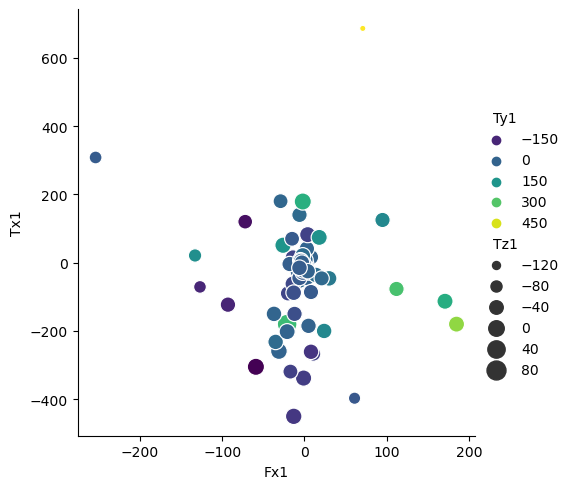

In [6]:
sns.relplot(data=df, x="Fx1", y="Tx1", hue="Ty1", size="Tz1", sizes=(20, 200), palette="viridis")

c:\Users\Owner\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


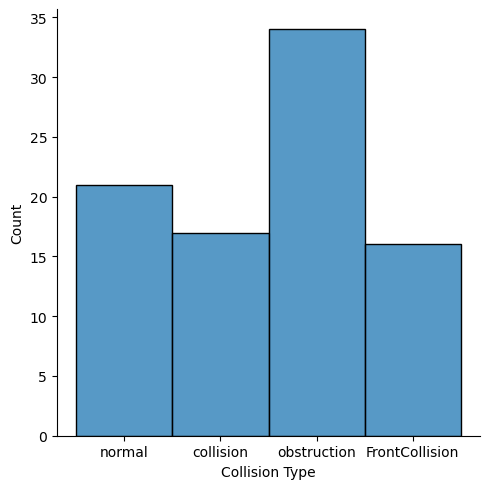

In [9]:
sns.displot(df['Collision Type'], bins=4, kde=False)

This plot shows the most common robotic movement encountered to be obstructions.

In [30]:
# Get all columns that start with 'Fx'
FxColumns = [col for col in df.columns if col.startswith('Fx')]

# Initialize dictionaries to store max and min values
MaxFxValues = {}
MinFxValues = {}
MaxTxValues = {}
MinTxValues = {}

# Loop over the 'Fx' columns
for col in FxColumns:
    MaxFxValues[col] = df[col].max()
    MinFxValues[col] = df[col].min()
    MaxTxValues[col] = df[col].max()
    MinTxValues[col] = df[col].min()



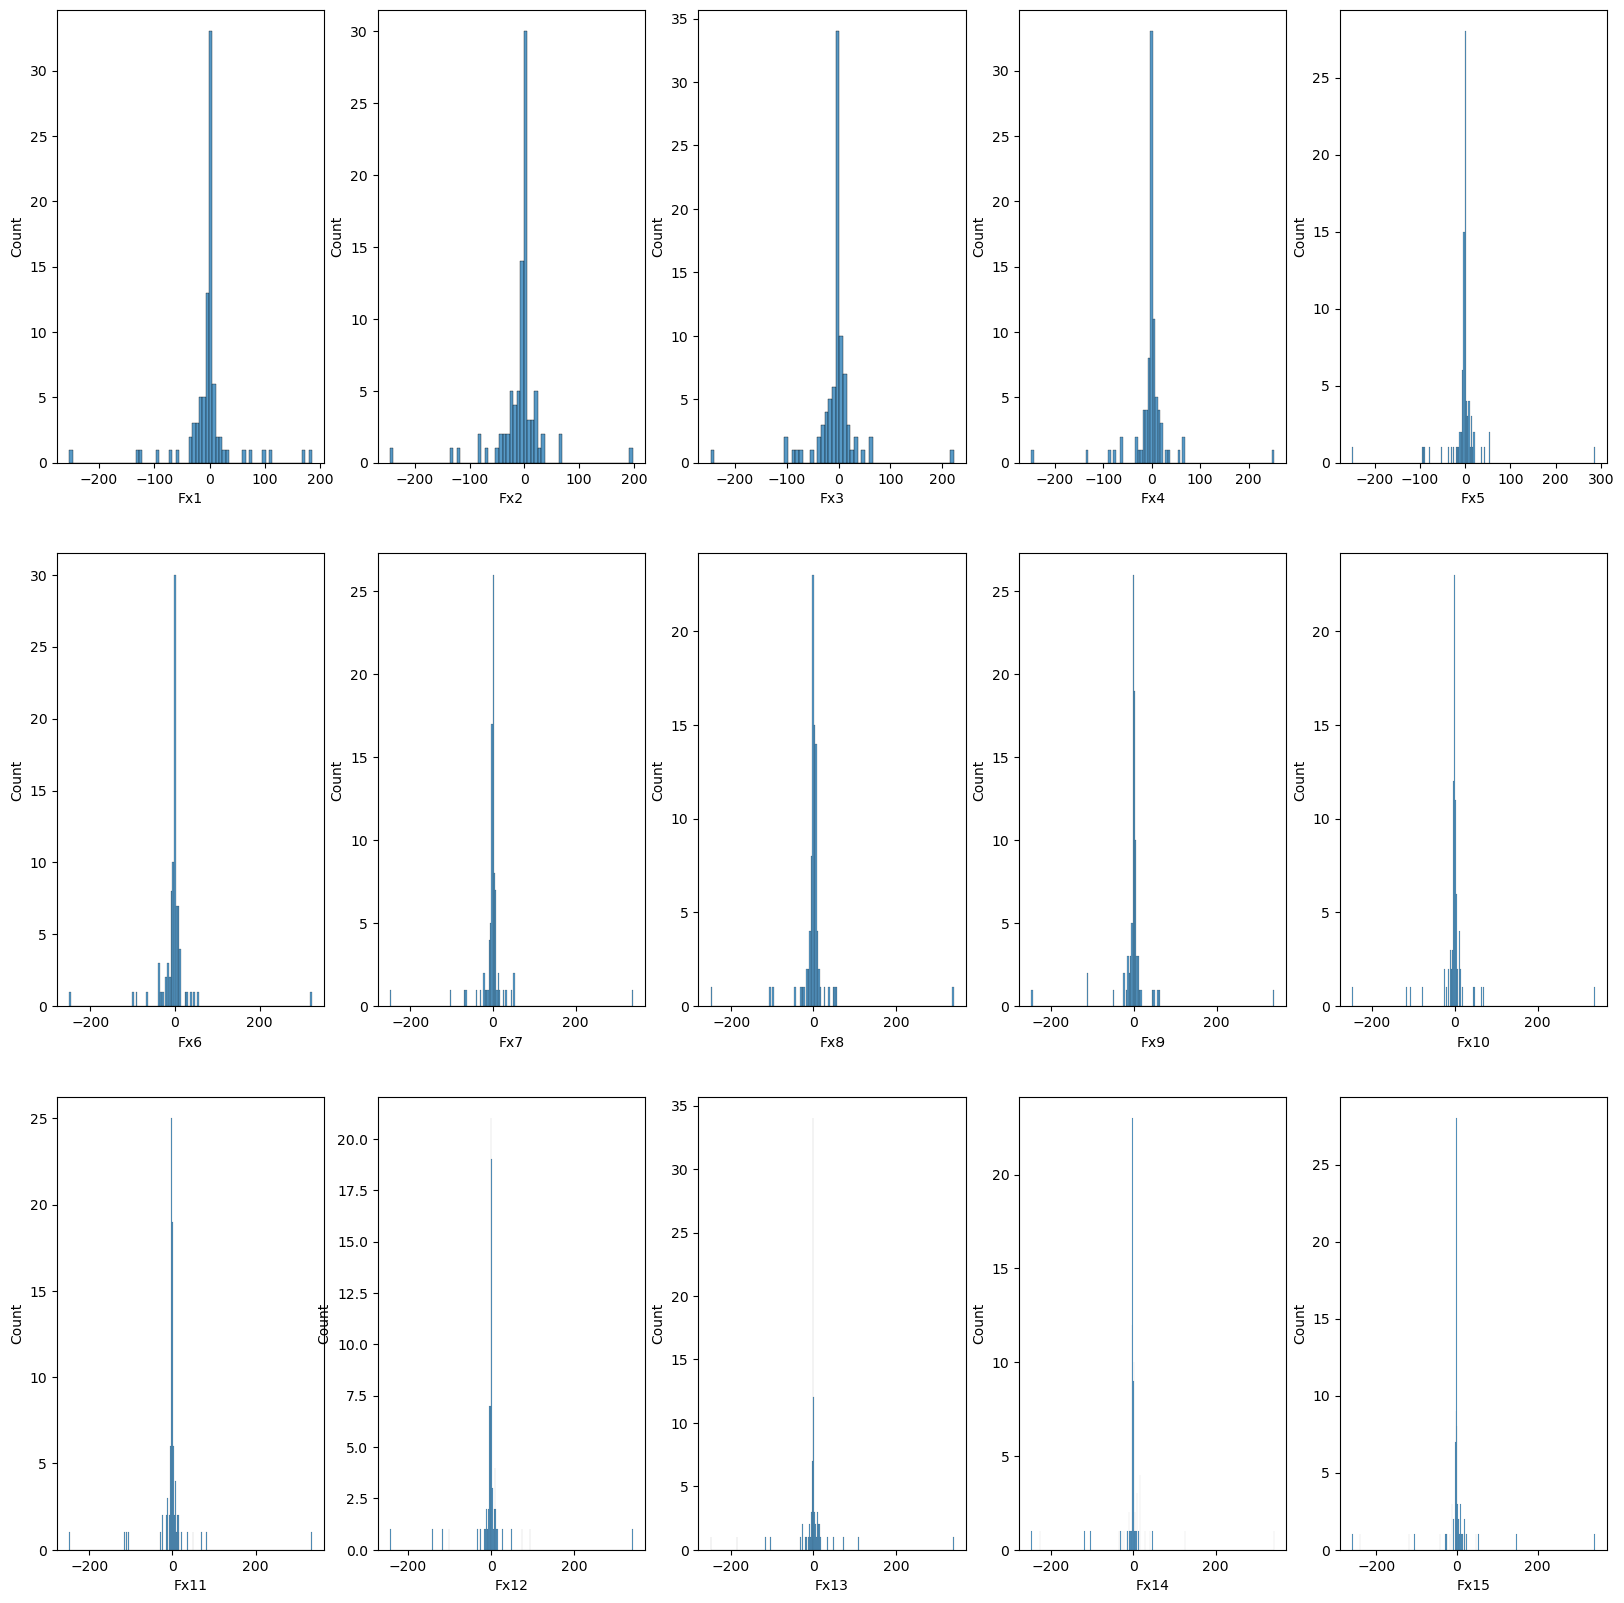

In [56]:
fig, axs = plt.subplots(3, 5, figsize=(20, 20))
for ax, col in zip(axs.flatten(), FxColumns):
    sns.histplot(df[col], ax=ax)


plt.show()


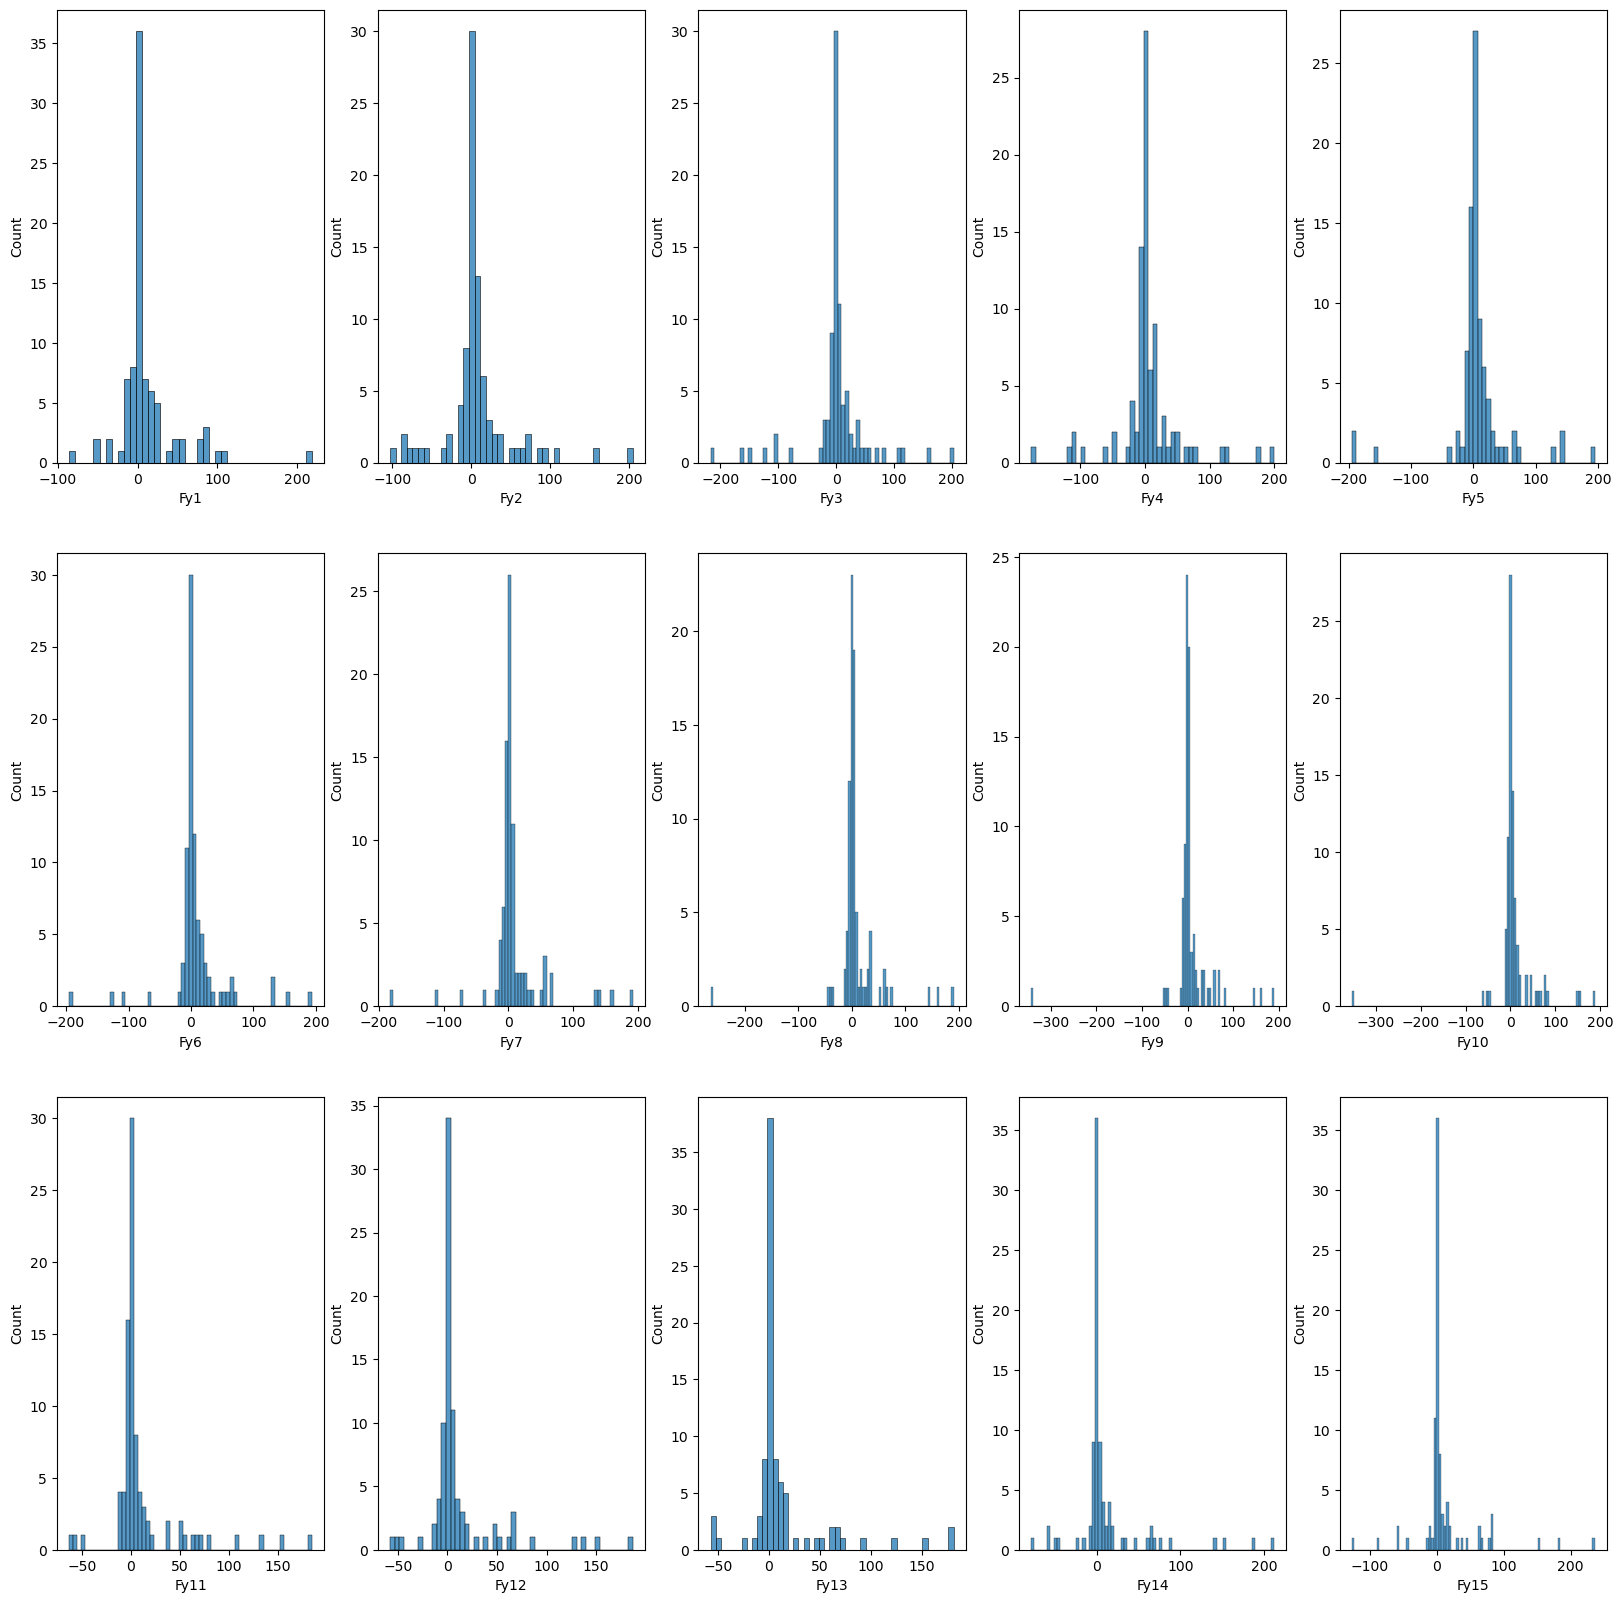

In [57]:
FyColumns = [col for col in df.columns if col.startswith('Fy')]
fig, axs = plt.subplots(3, 5, figsize=(20, 20))
for ax, col in zip(axs.flatten(), FyColumns):
    sns.histplot(df[col], ax=ax)


plt.show()


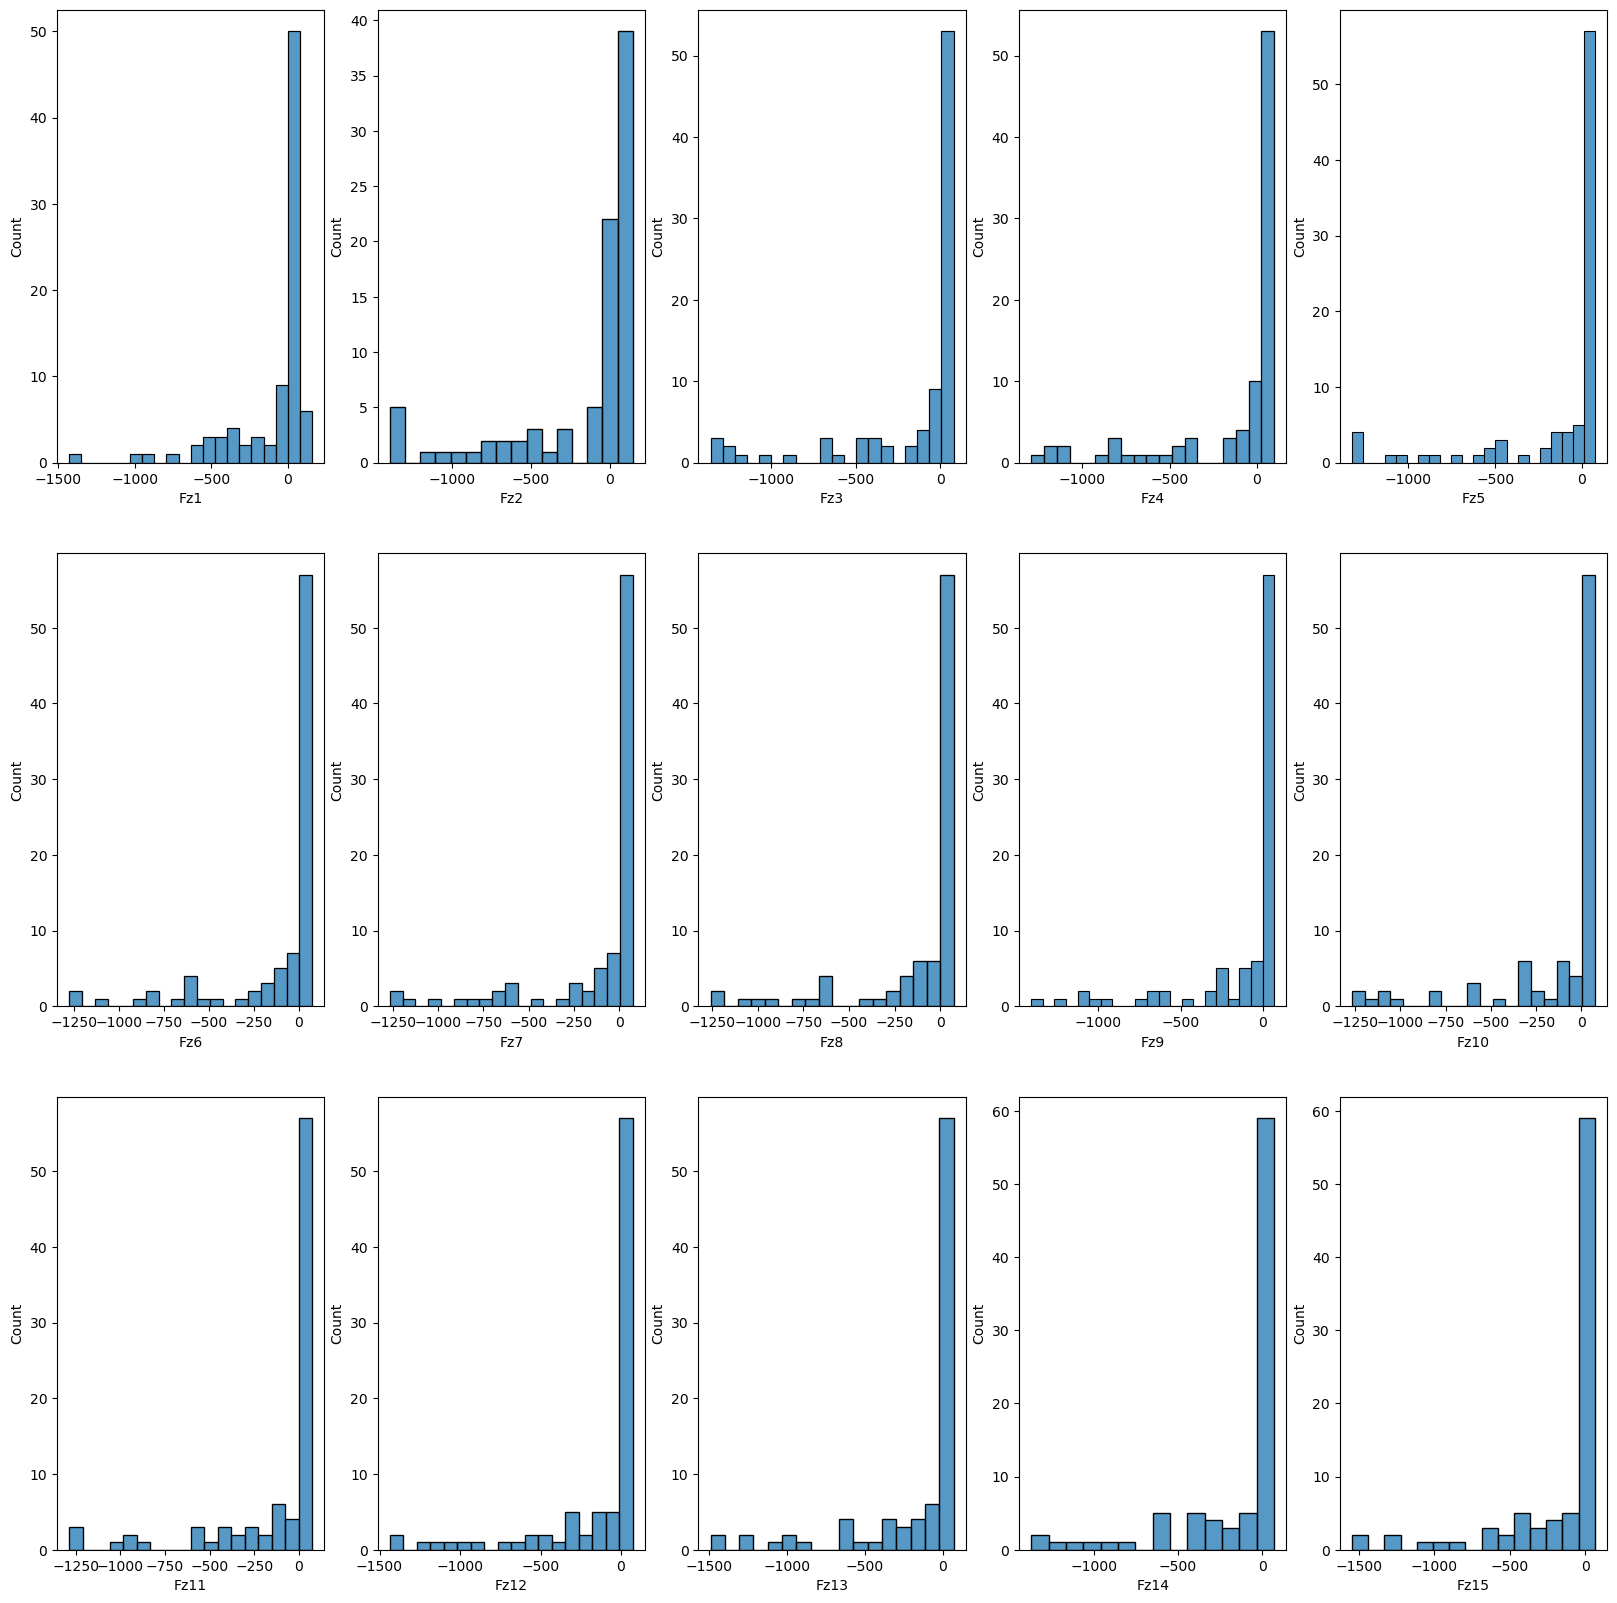

In [60]:

FzColumns = [col for col in df.columns if col.startswith('Fz')]
fig, axs = plt.subplots(3, 5, figsize=(20, 20))
for ax, col in zip(axs.flatten(), FzColumns):
    sns.histplot(df[col], ax=ax)


plt.show()

c:\Users\Owner\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


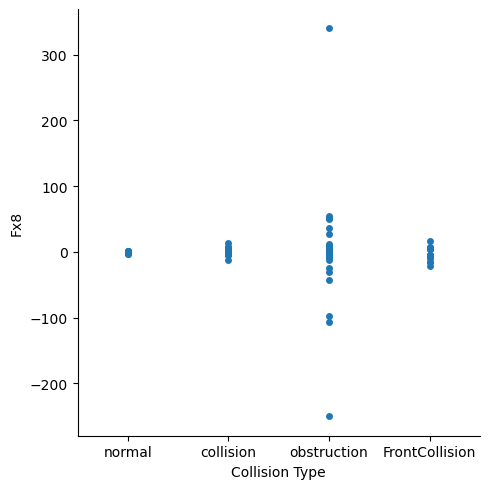

In [68]:
sns.catplot(data=df, x="Collision Type", y="Fx8", jitter=False)

Take Average of each Tx, Ty, and Tz column, then take avg of Tx, Tz, Ty, overall

In [7]:
# Get all columns that start with 'Fx'
TxColumns = [col for col in df.columns if col.startswith('Tx')]
TyColumns = [col for col in df.columns if col.startswith('Ty')]
TzColumns = [col for col in df.columns if col.startswith('Tz')]
FxColumns = [col for col in df.columns if col.startswith('Fx')]
FyColumns = [col for col in df.columns if col.startswith('Fy')]
FzColumns = [col for col in df.columns if col.startswith('Fz')]

# Initialize dictionaries to store max and min values
AvgTxColValues = {}
AvgTyColValues = {}
AvgTzColValues = {}
AvgFxColValues = {}
AvgFyColValues = {}
AvgFzColValues = {}


# Loop over the 'Fx' columns
for col in TxColumns:
    AvgTxColValues[col] = df[col].mean()
for col in TyColumns:
    AvgTyColValues[col] = df[col].mean()
for col in TzColumns:
    AvgTzColValues[col] = df[col].mean()
for col in FxColumns:
    AvgFxColValues[col] = df[col].mean()
for col in FyColumns:
    AvgFyColValues[col] = df[col].mean()
for col in FzColumns:
    AvgFzColValues[col] = df[col].mean()


    

In [14]:
print(AvgTxColValues)

AvgCols = pd.DataFrame([AvgTxColValues, AvgTyColValues, AvgTzColValues, AvgFxColValues, AvgFyColValues, AvgFzColValues])

print(AvgCols)

{'Tx1': -39.70454545454545, 'Tx2': -49.875, 'Tx3': -37.78409090909091, 'Tx4': -40.27272727272727, 'Tx5': -42.30681818181818, 'Tx6': -36.46590909090909, 'Tx7': -29.568181818181817, 'Tx8': -36.34090909090909, 'Tx9': -35.27272727272727, 'Tx10': -35.78409090909091, 'Tx11': -40.05681818181818, 'Tx12': -40.0, 'Tx13': -41.75, 'Tx14': -40.76136363636363, 'Tx15': -39.47727272727273}
         Tx1     Tx2        Tx3        Tx4        Tx5        Tx6        Tx7  \
0 -39.704545 -49.875 -37.784091 -40.272727 -42.306818 -36.465909 -29.568182   
1        NaN     NaN        NaN        NaN        NaN        NaN        NaN   
2        NaN     NaN        NaN        NaN        NaN        NaN        NaN   
3        NaN     NaN        NaN        NaN        NaN        NaN        NaN   
4        NaN     NaN        NaN        NaN        NaN        NaN        NaN   
5        NaN     NaN        NaN        NaN        NaN        NaN        NaN   

         Tx8        Tx9       Tx10  ...         Fz6         Fz7      

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(10, 10))
for ax, col in zip(axs.flatten(), FxColumns):
    sns.catplot(data=AvgFxColValues, kind='bar', ax=ax)
    sns.catplot(data=AvgFyColValues, kind='bar', ax=ax)
    sns.catplot(data=AvgFzColValues, kind='bar', ax=ax)
    sns.catplot(data=AvgTxColValues, kind='bar', ax=ax)
    sns.catplot(data=AvgTyColValues, kind='bar', ax=ax)
    sns.catplot(data=AvgTzColValues, kind='bar', ax=ax)



plt.show()



In [ ]:
sns.catplot(data=AvgFxColValues, x=AvgFxColValues.index, kind='bar', ax=ax)


In [ ]:
sns.catplot(data=AvgFxColValues, x="AvgFxColValues.Values()" kind='bar', ax=ax)
sns.catplot(data=AvgFyColValues, kind='bar', ax=ax)
sns.catplot(data=AvgFzColValues, kind='bar', ax=ax)
sns.catplot(data=AvgTxColValues, kind='bar', ax=ax)
sns.catplot(data=AvgTyColValues, kind='bar', ax=ax)
sns.catplot(data=AvgTzColValues, kind='bar', ax=ax)

In [8]:
import statistics

# Get the values from the dictionary
TxValues = list(AvgTxColValues.values())
TyValues = list(AvgTyColValues.values())
TzValues = list(AvgTzColValues.values())
FxValues = list(AvgFxColValues.values())
FyValues = list(AvgFyColValues.values())
FzValues = list(AvgFzColValues.values())

# Calculate the average
TxAverage = statistics.mean(TxValues)
TyAverage = statistics.mean(TyValues)
TzAverage = statistics.mean(TzValues)
FxAverage = statistics.mean(FxValues)
FyAverage = statistics.mean(FyValues)
FzAverage = statistics.mean(FzValues)


print("Average of AvgTxColValues:", TxAverage)
print("Average of AvgTyColValues:", TyAverage)
print("Average of AvgTzColValues:", TzAverage)
print("Average of AvgFxColValues:", FxAverage)
print("Average of AvgFyColValues:", FyAverage)
print("Average of AvgFzColValues:", FzAverage)

Average of AvgTxColValues: -39.028030303030306
Average of AvgTyColValues: -4.517424242424243
Average of AvgTzColValues: 0.8681818181818182
Average of AvgFxColValues: -2.3454545454545452
Average of AvgFyColValues: 8.913636363636364
Average of AvgFzColValues: -128.21439393939394


In [9]:
Avgdf = pd.DataFrame([TxAverage, TyAverage, TzAverage, FxAverage, FyAverage, FzAverage], index=['AvgTx', 'AvgTy', 'AvgTz', 'AvgFx', 'AvgFy', 'AvgFz'], columns=['Average'])
print(Avgdf)

          Average
AvgTx  -39.028030
AvgTy   -4.517424
AvgTz    0.868182
AvgFx   -2.345455
AvgFy    8.913636
AvgFz -128.214394


In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
for ax, col in zip(axs.flatten(), FxColumns):
    sns.histplot(df[col], ax=ax)


plt.show()

Categorical Scatterplot

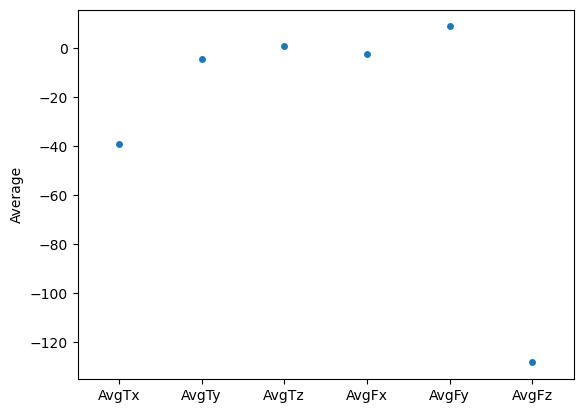

In [10]:
stripplot = sns.stripplot(data=Avgdf, x=Avgdf.index, y='Average')

c:\Users\Owner\anaconda3\Lib\site-packages\seaborn\categorical.py:3544: UserWarning: 23.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\Owner\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
c:\Users\Owner\anaconda3\Lib\site-packages\seaborn\categorical.py:3544: UserWarning: 47.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\Owner\anaconda3\Lib\site-packages\seaborn\categorical.py:3544: UserWarning: 38.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


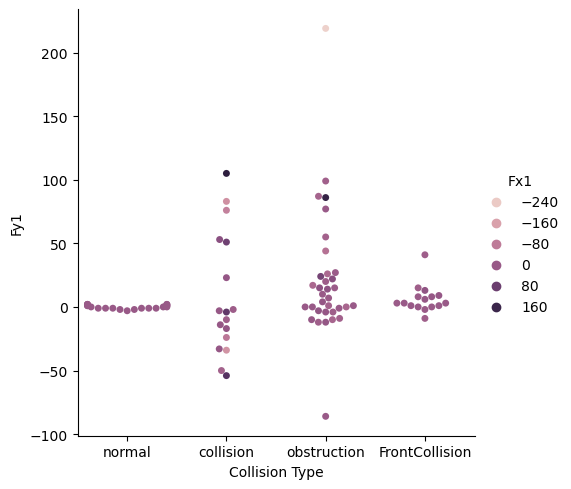

In [12]:
sns.catplot(data=df, x='Collision Type', y='Fy1', hue='Fx1', kind='swarm')

c:\Users\Owner\anaconda3\Lib\site-packages\seaborn\categorical.py:3544: UserWarning: 28.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\Owner\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
c:\Users\Owner\anaconda3\Lib\site-packages\seaborn\categorical.py:3544: UserWarning: 47.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\Owner\anaconda3\Lib\site-packages\seaborn\categorical.py:3544: UserWarning: 38.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


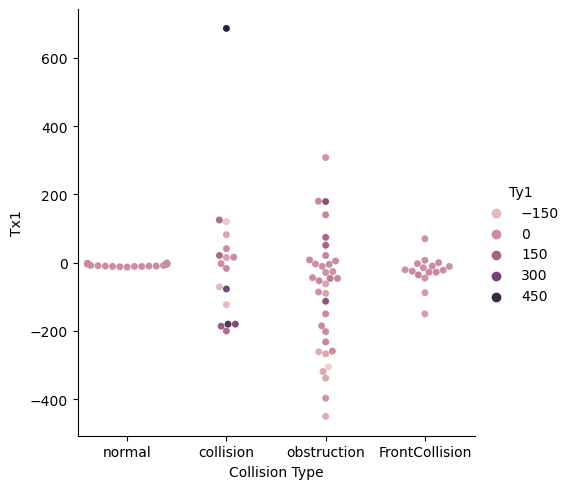

In [13]:
sns.catplot(data=df, x='Collision Type', y='Tx1', hue='Ty1', kind='swarm')

In [ ]:
sns.catplot(data=df, x='Collision Type', y='Tz1', kind='box')


In [21]:
print(df['Tz1'])

0      0
1      0
2      0
3     -1
4      0
      ..
83   -11
84     0
85    -7
86    13
87     3
Name: Tz1, Length: 88, dtype: int64


88


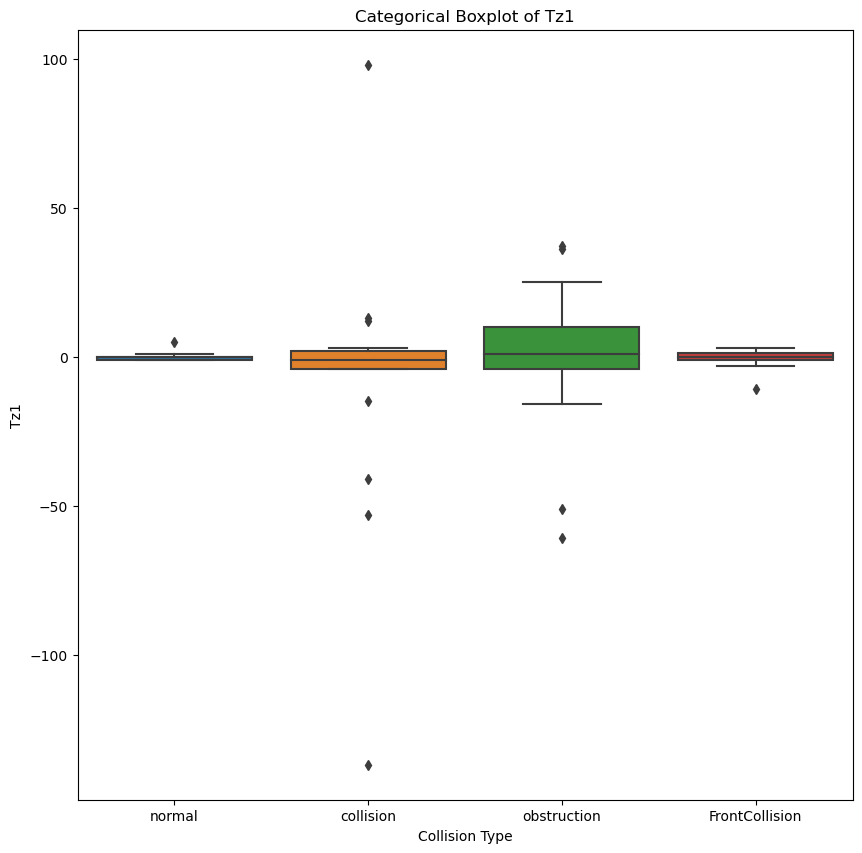

In [32]:
# TzOneMean = statistics.mean(df[['Collision Type', 'Tz1']])
ColAmt = len(df['Tz1'])
print(ColAmt)
TzOneDf = pd.DataFrame()
for value in (df['Tz1']):

        NormalTzOneDf = df[df['Collision Type'] == 'normal'][['Collision Type', 'Tz1']]
    
        CollisionTzOneDf = df[df['Collision Type'] == 'collision'][['Collision Type', 'Tz1']]
  
        ObstructionTzOneDf = df[df['Collision Type'] == 'obstruction'][['Collision Type', 'Tz1']]
   
        FCTzOneDf = df[df['Collision Type'] == 'FrontCollision'][['Collision Type', 'Tz1']]

TzOneDf = pd.concat([NormalTzOneDf, CollisionTzOneDf, ObstructionTzOneDf, FCTzOneDf], axis=0)


plt.figure(figsize=(10, 10))
sns.boxplot(data=TzOneDf, x='Collision Type', y='Tz1')
plt.title("Categorical Boxplot of Tz1")
plt.show()

In [37]:
Mediandf = pd.DataFrame()

for column in df.select_dtypes(include=np.number):
    Mediandf[column] = df[column].median()

print(Mediandf)
# sns.catplot(data=df, x='Collision Type', 

Empty DataFrame
Columns: [Fx1, Fy1, Fz1, Tx1, Ty1, Tz1, Fx2, Fy2, Fz2, Tx2, Ty2, Tz2, Fx3, Fy3, Fz3, Tx3, Ty3, Tz3, Fx4, Fy4, Fz4, Tx4, Ty4, Tz4, Fx5, Fy5, Fz5, Tx5, Ty5, Tz5, Fx6, Fy6, Fz6, Tx6, Ty6, Tz6, Fx7, Fy7, Fz7, Tx7, Ty7, Tz7, Fx8, Fy8, Fz8, Tx8, Ty8, Tz8, Fx9, Fy9, Fz9, Tx9, Ty9, Tz9, Fx10, Fy10, Fz10, Tx10, Ty10, Tz10, Fx11, Fy11, Fz11, Tx11, Ty11, Tz11, Fx12, Fy12, Fz12, Tx12, Ty12, Tz12, Fx13, Fy13, Fz13, Tx13, Ty13, Tz13, Fx14, Fy14, Fz14, Tx14, Ty14, Tz14, Fx15, Fy15, Fz15, Tx15, Ty15, Tz15]
Index: []

[0 rows x 90 columns]


In [53]:

# Initialize an empty DataFrame to store the results
Mediandf = pd.DataFrame()
MaxMediandf = pd.DataFrame()

# Get the list of unique collision types
collision_types = df['Collision Type'].unique()

# Loop over each collision type
for collision_type in collision_types:
    # Filter the DataFrame for the current collision type
    filtered_df = df[df['Collision Type'] == collision_type]
    
    # Calculate the median of each numeric column
    median_values = filtered_df.select_dtypes(include=[np.number]).median()
    
    # Add the collision type to the Series
    median_values['Collision Type'] = collision_type
    
    # Append the results to the Mediandf DataFrame
    Mediandf = pd.concat([Mediandf, pd.DataFrame(median_values).T], ignore_index=True)
    MaxMediandf = pd.concat([Mediandf, pd.DataFrame(median_values).T], ignore_index=True)

# Set the 'Collision Type' column as the index
Mediandf.set_index('Collision Type', inplace=True)


for column in Mediandf.select_dtypes(include=np.number):
    MaxMediandf[column] = Mediandf[column].max()
# Print the resulting DataFrame

MaxMediandf[column] = Mediandf[column].max()



In [54]:
print(MaxMediandf)

   Fx1  Fy1    Fz1   Tx1  Ty1  Tz1  Fx2  Fy2    Fz2   Tx2  ...  Tx14 Ty14  \
0 -1.0  0.0   61.0  -8.0 -2.0  0.0 -1.0  0.0   60.0  -6.0  ...  -8.0 -3.0   
1  3.0 -4.0   59.0  -3.0  8.0 -1.0  0.0  6.0   61.0 -21.0  ...  -6.0 -4.0   
2 -3.5  8.5 -294.5 -49.5  0.0  1.0 -8.0  9.5 -455.0 -88.0  ... -14.0 -5.0   
3 -1.5  3.0   42.0 -21.5 -7.5  0.0 -1.5  3.5   39.0 -22.5  ... -34.0 -6.0   
4 -1.5  3.0   42.0 -21.5 -7.5  0.0 -1.5  3.5   39.0 -22.5  ... -34.0 -6.0   

  Tz14 Fx15 Fy15   Fz15  Tx15 Ty15 Tz15  Collision Type  
0  0.0 -1.0  0.0   60.0  -8.0 -3.0  1.5          normal  
1 -1.0  0.0  1.0   63.0  -8.0 -3.0  1.5       collision  
2 -1.0  0.0  3.5 -332.5 -13.5 -5.0  1.5     obstruction  
3  2.0 -2.5  9.0  -13.0 -35.0 -5.0  1.5  FrontCollision  
4  2.0 -2.5  9.0  -13.0 -35.0 -5.0  1.5  FrontCollision  

[5 rows x 91 columns]


<Figure size 1000x1000 with 0 Axes>

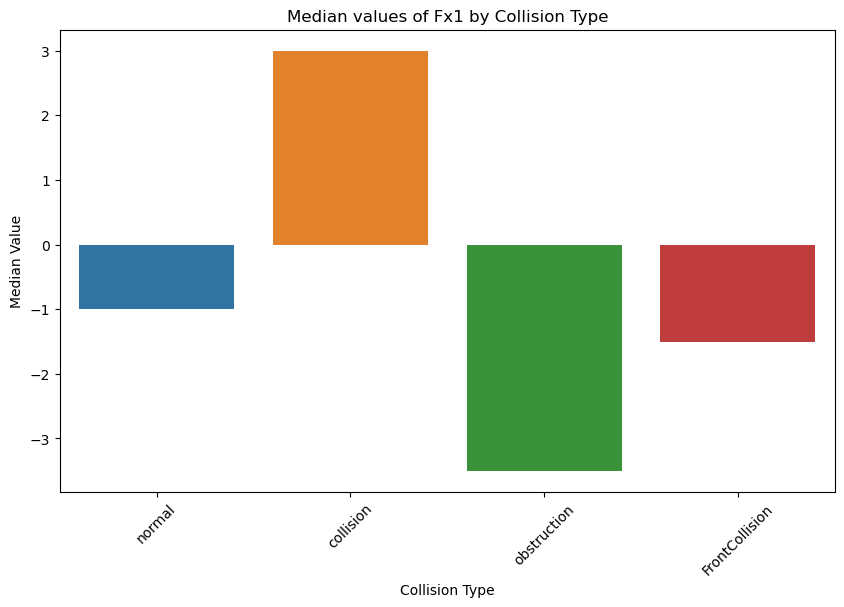

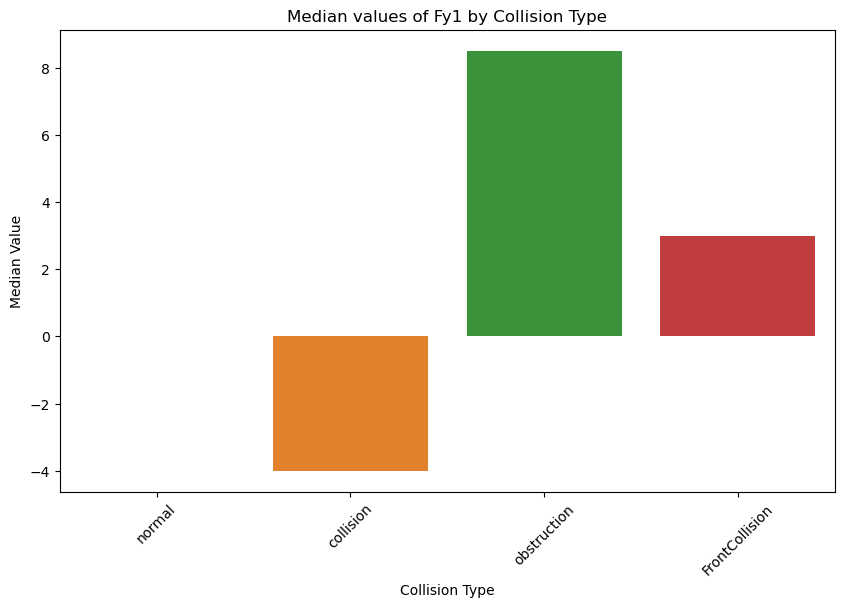

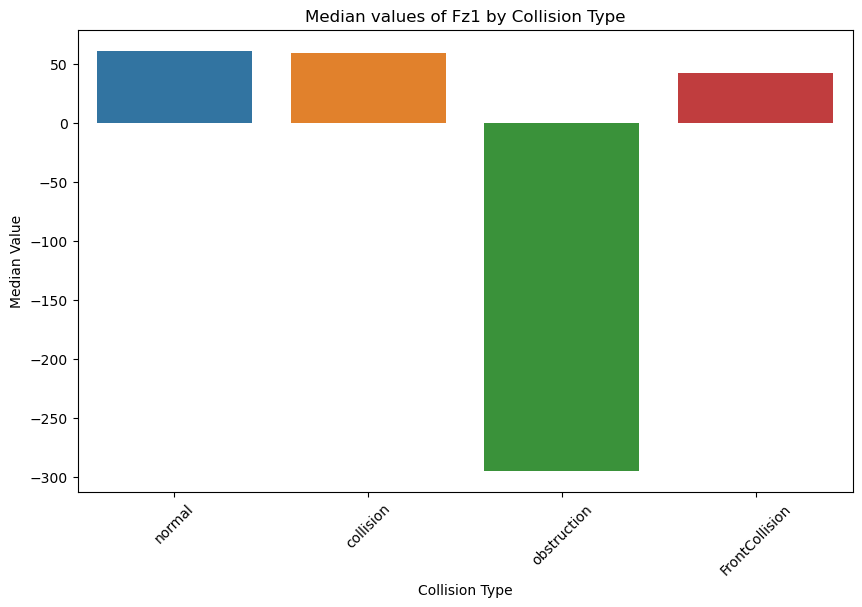

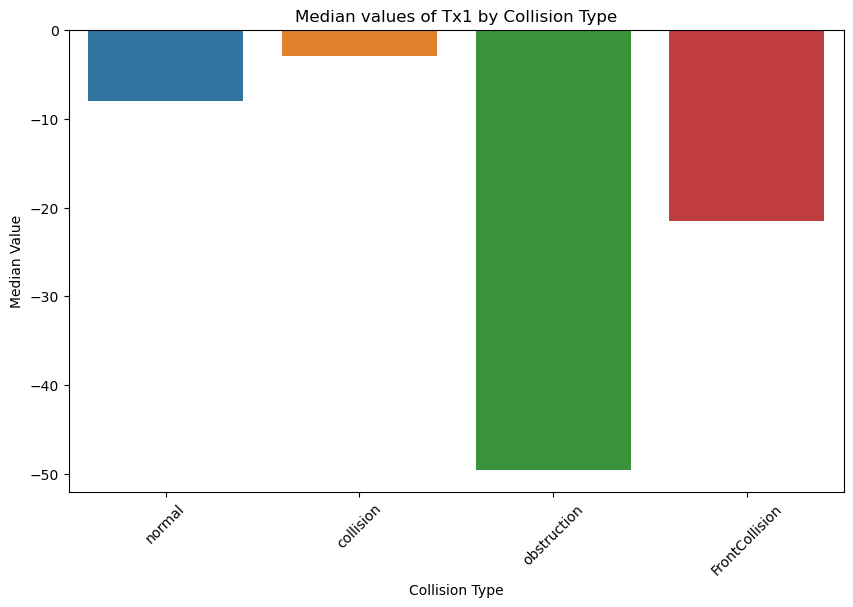

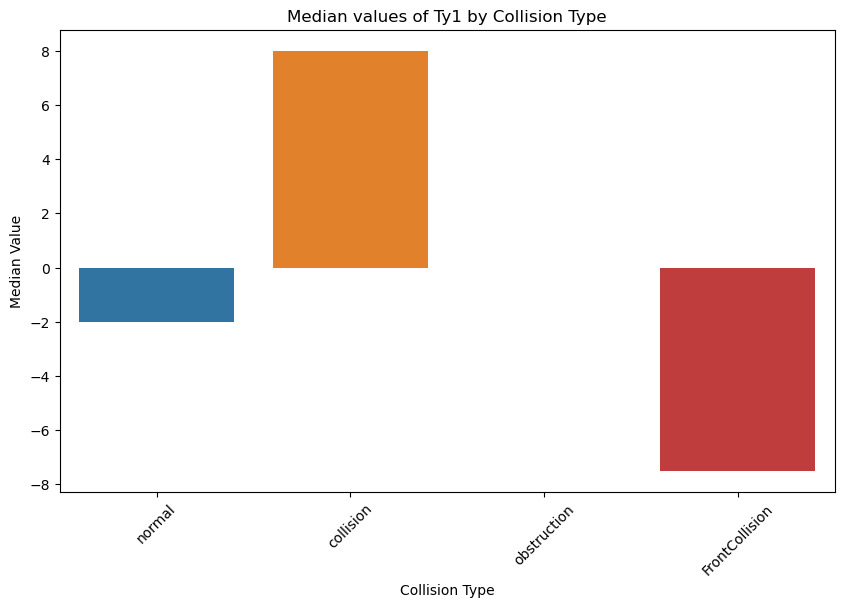

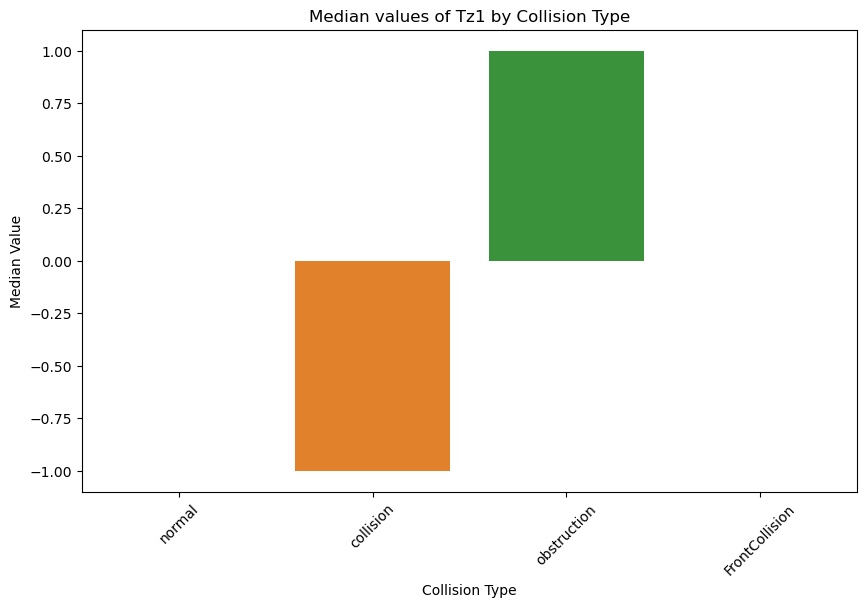

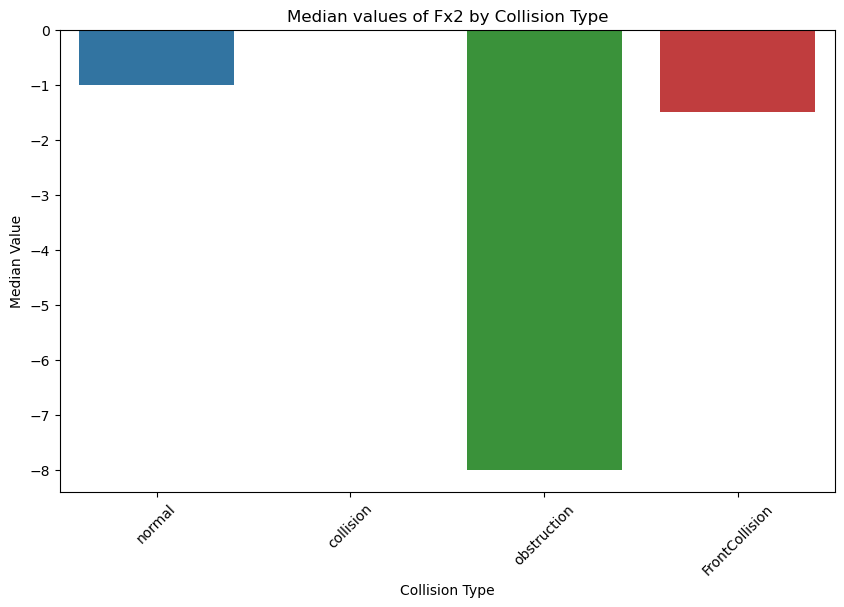

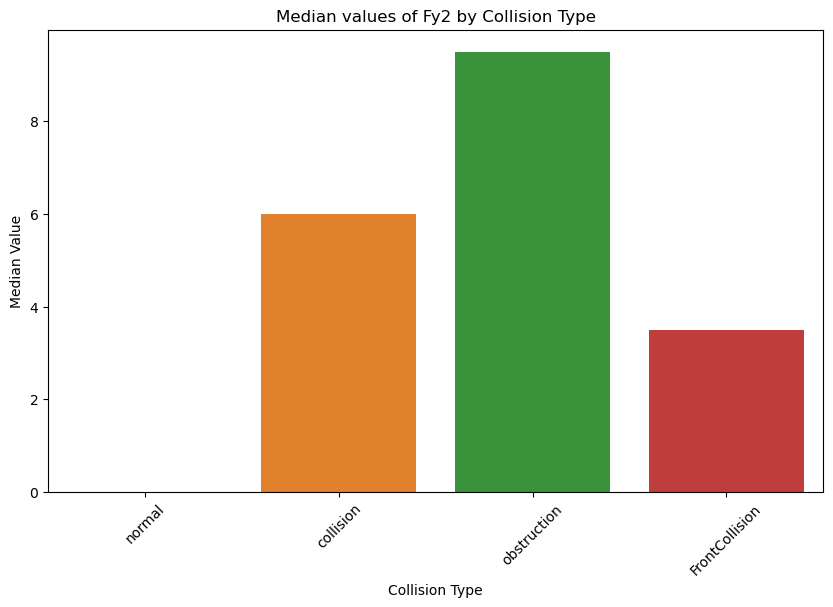

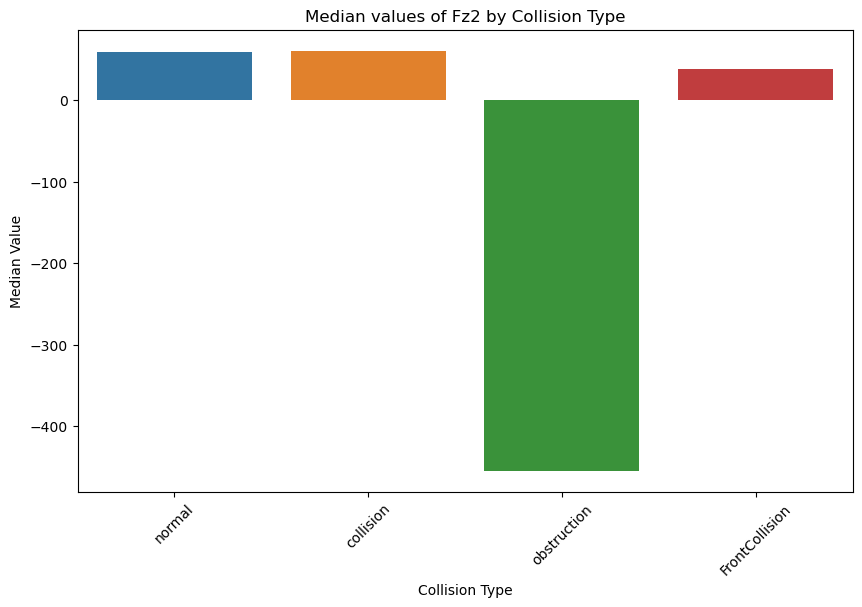

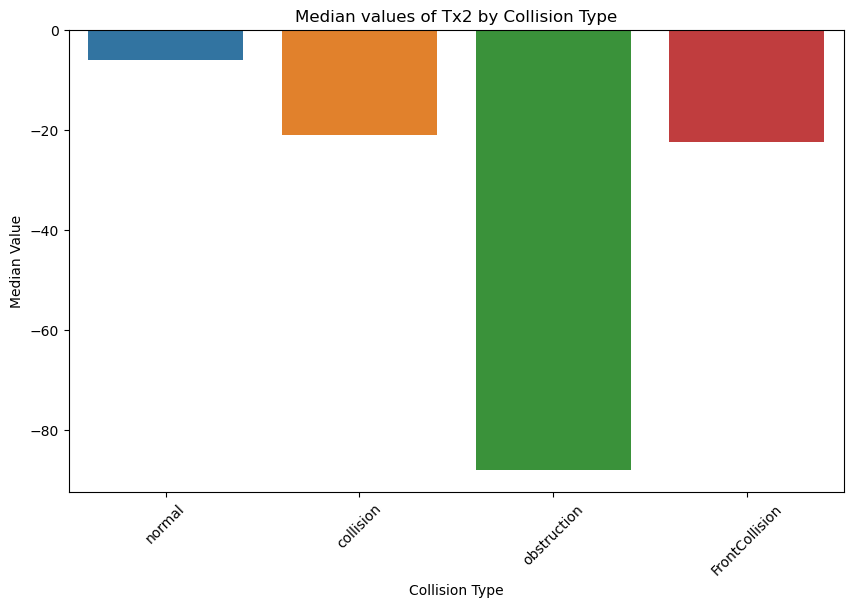

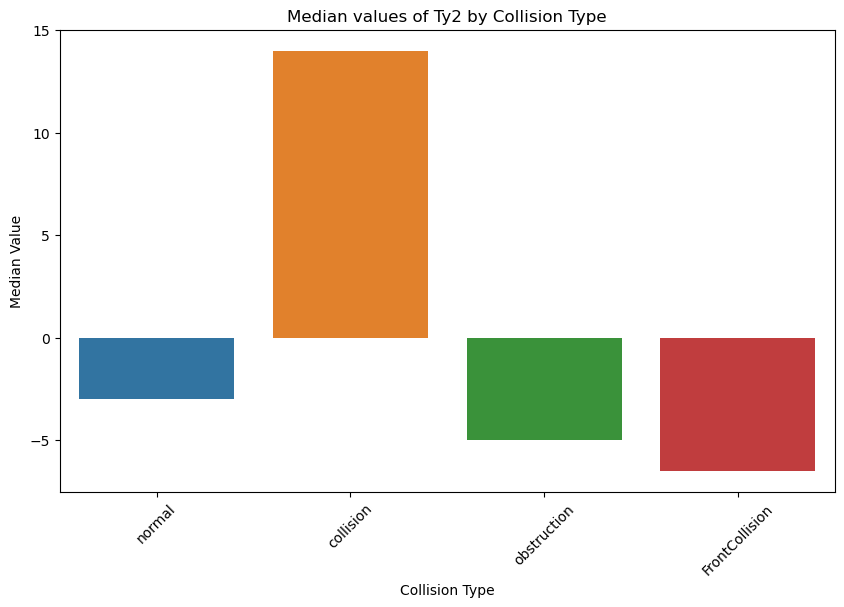

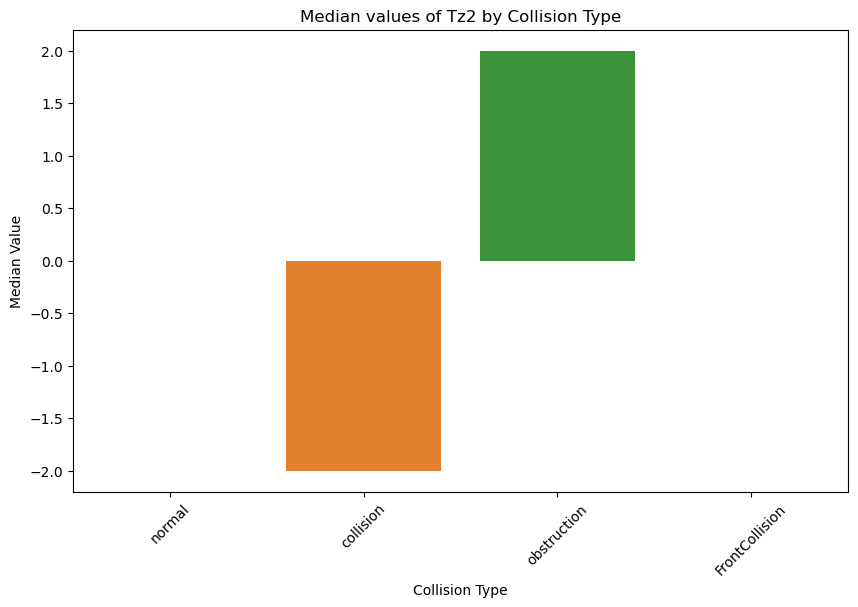

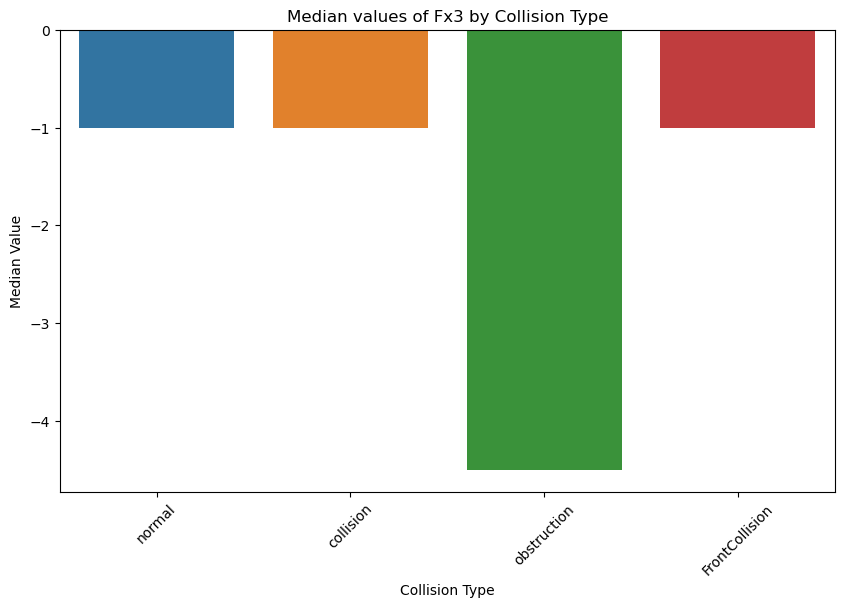

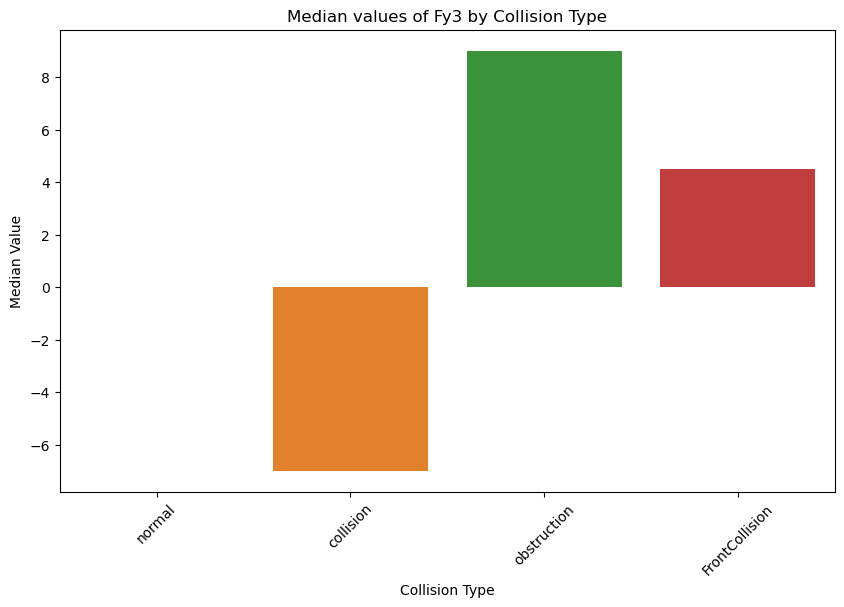

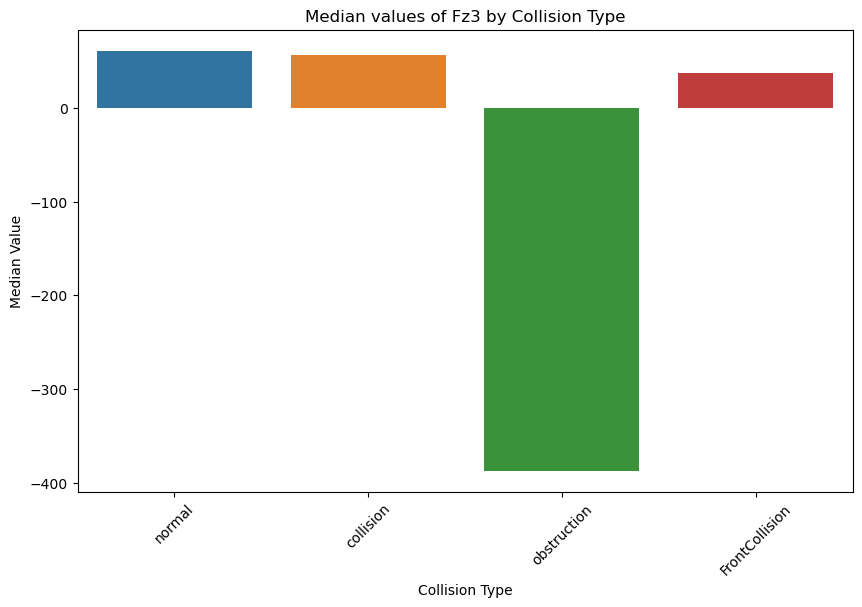

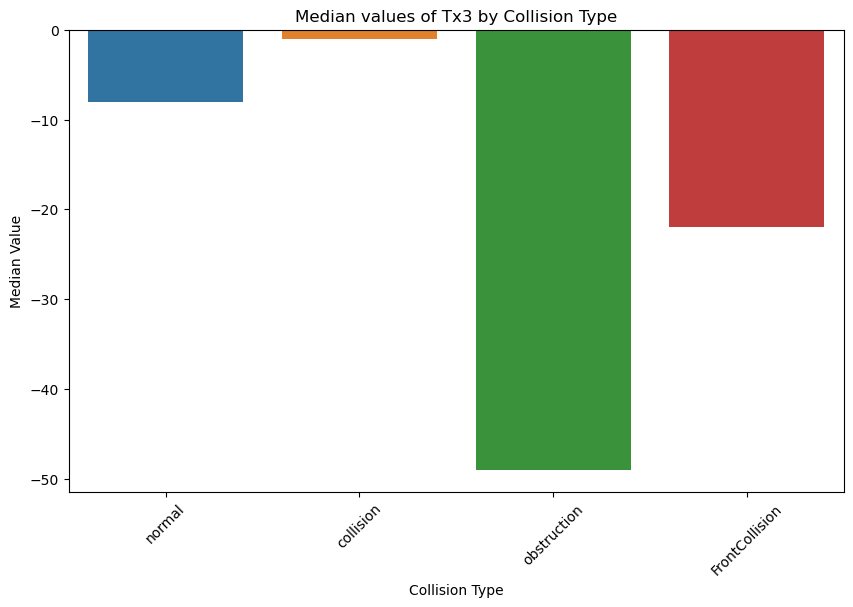

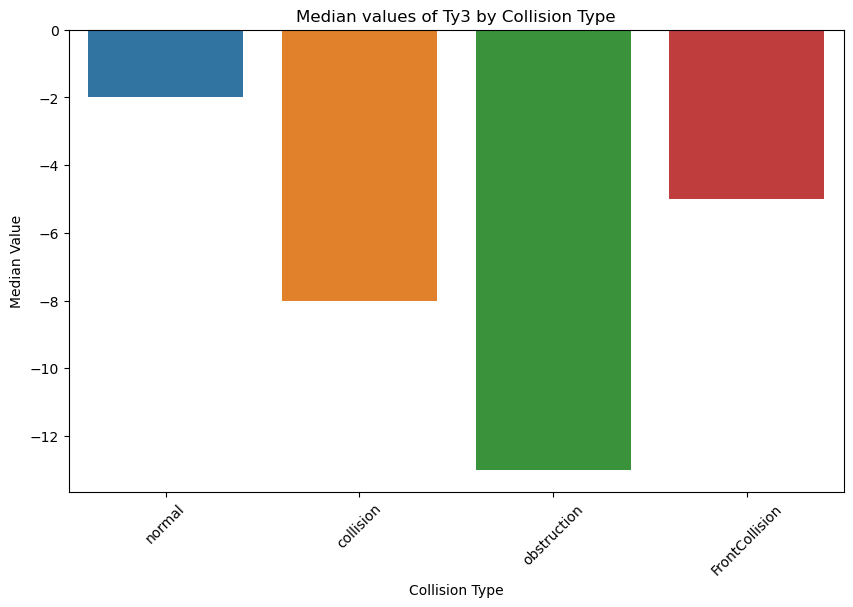

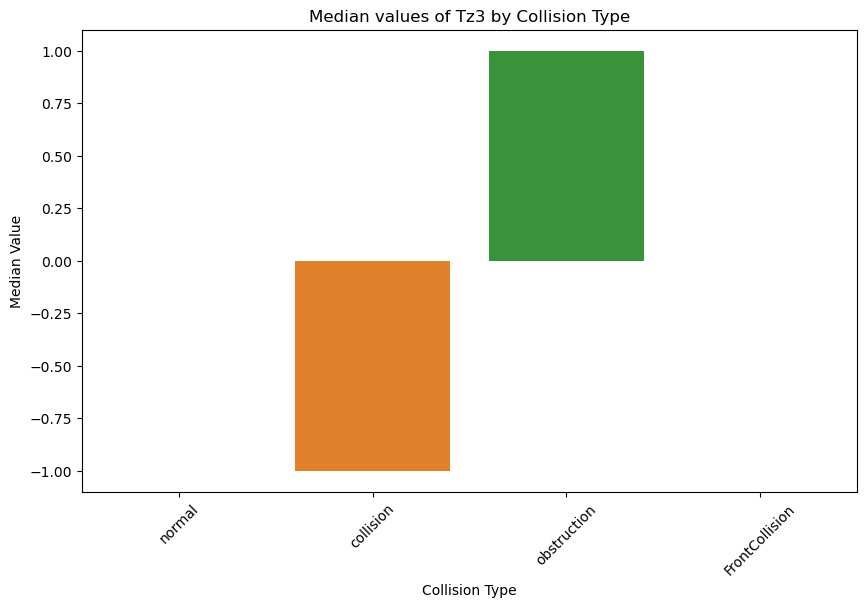

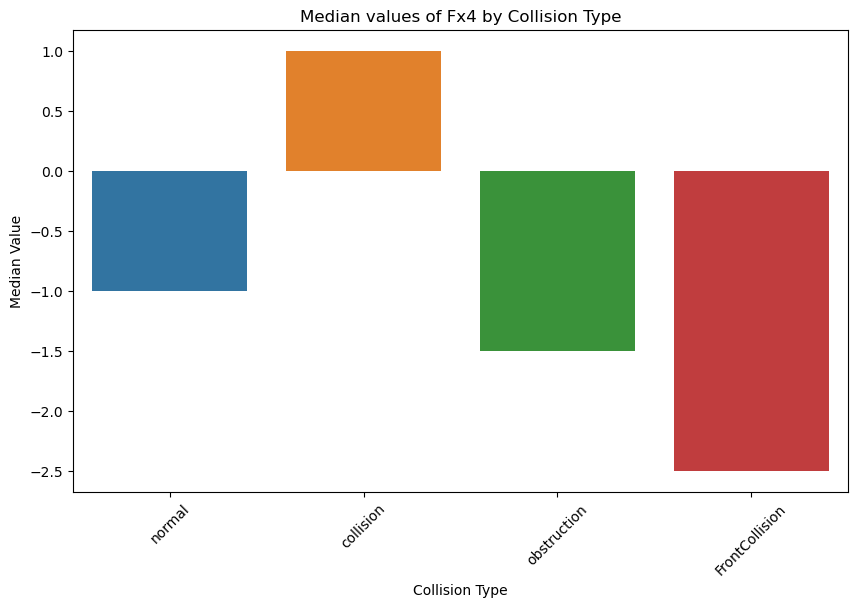

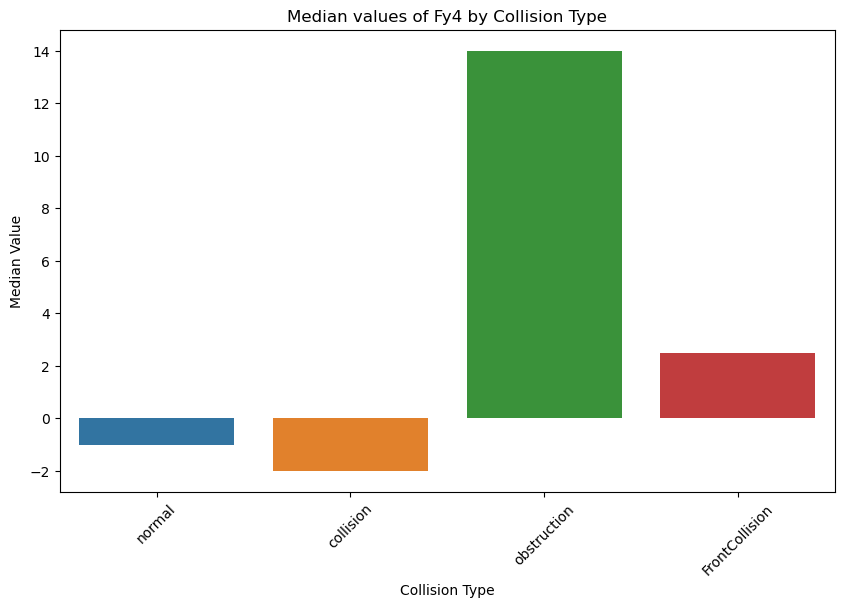

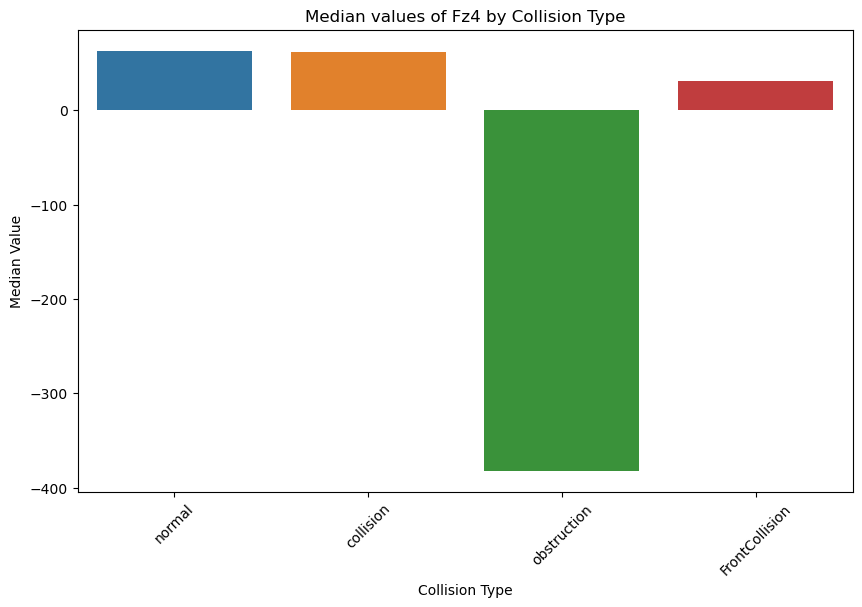

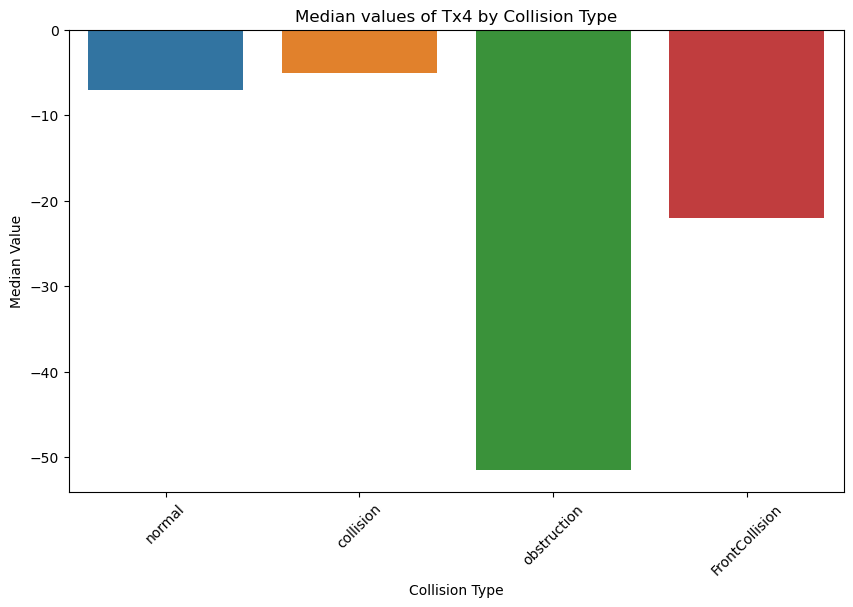

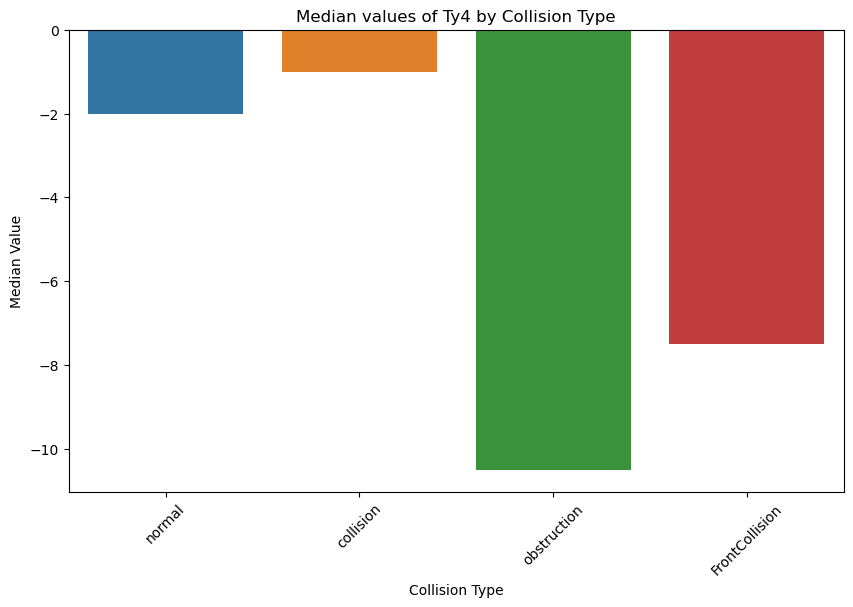

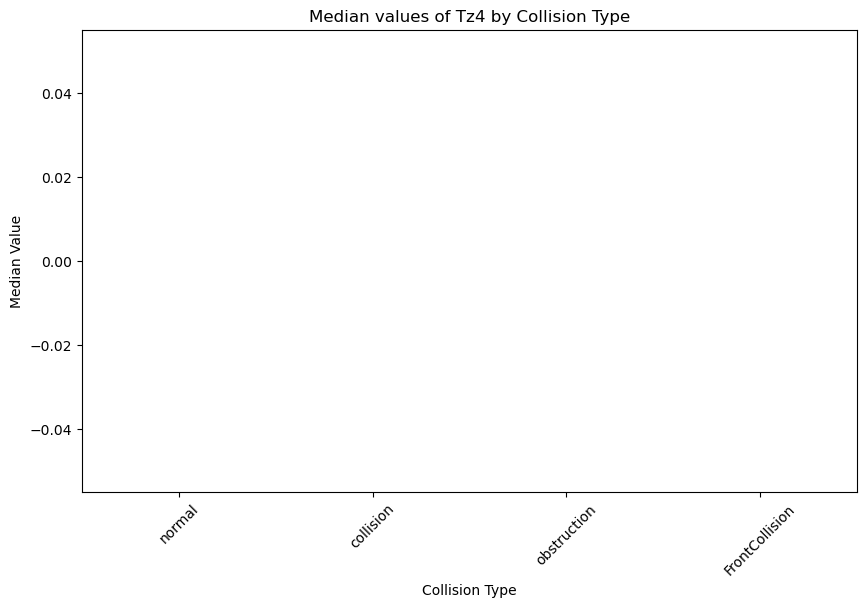

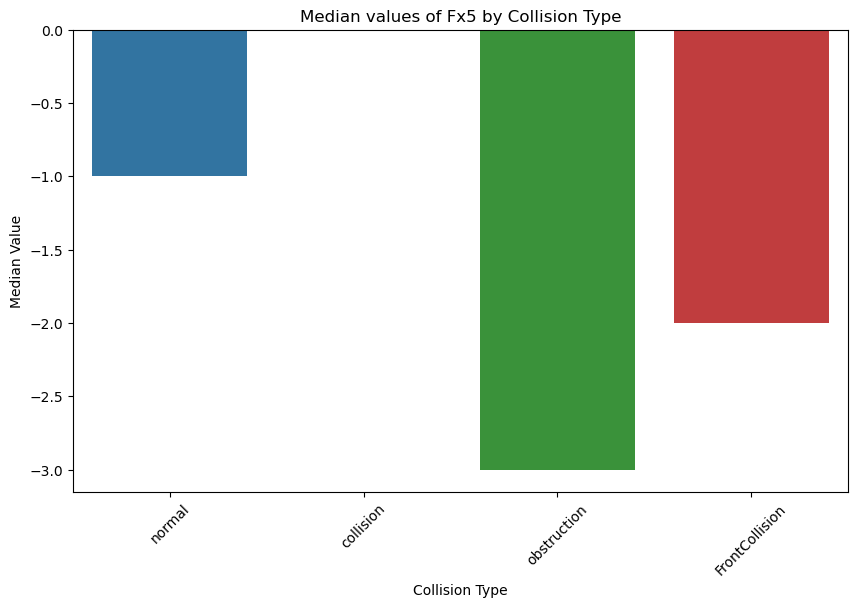

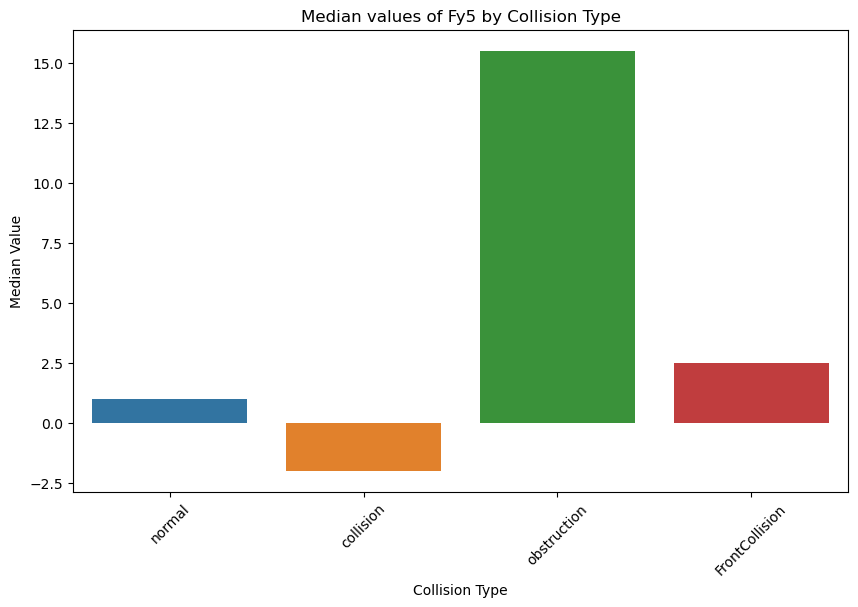

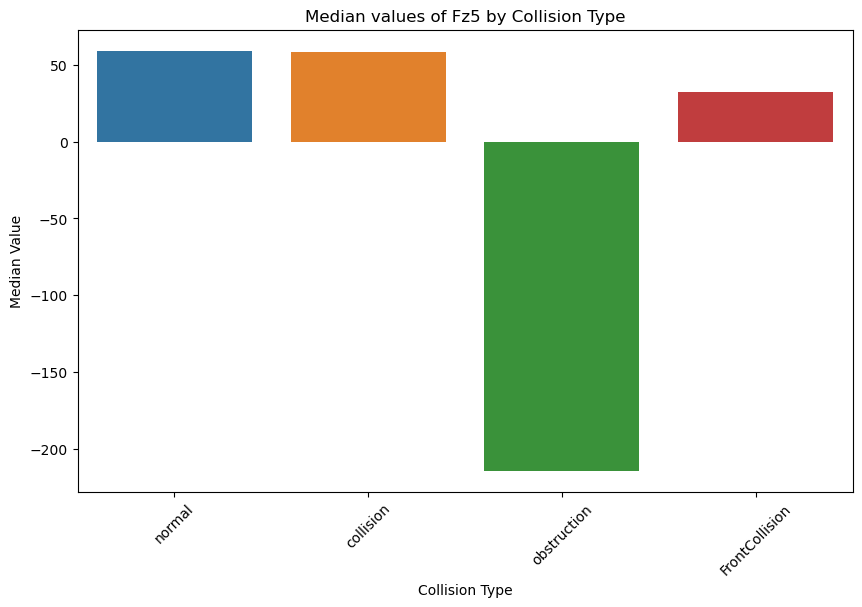

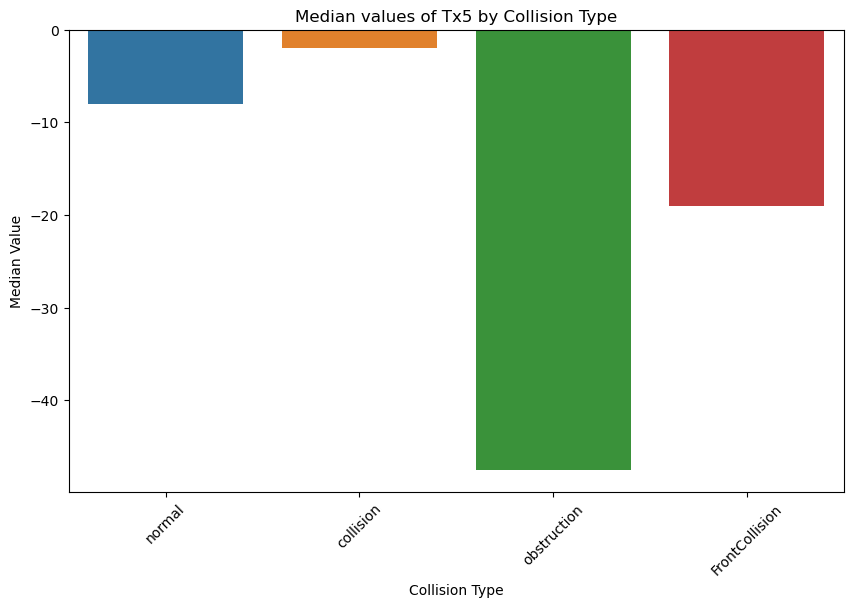

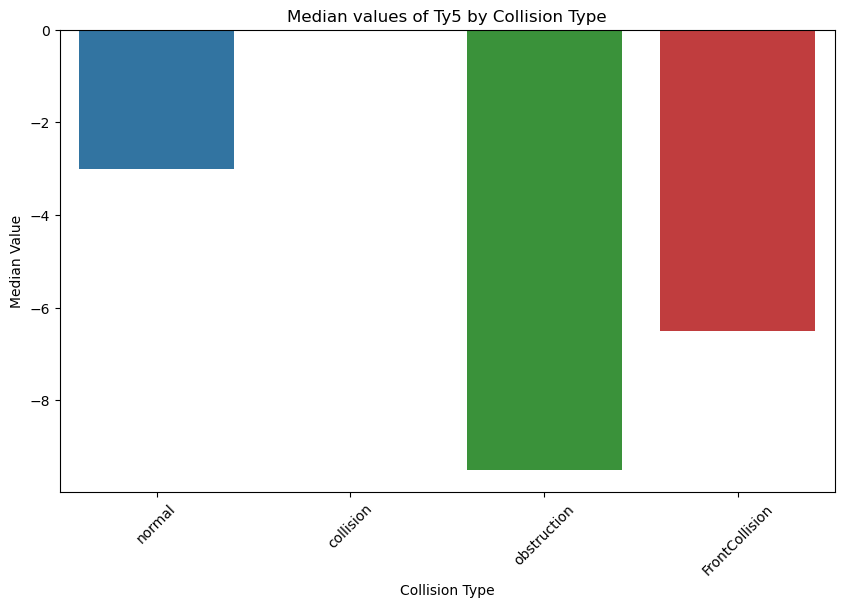

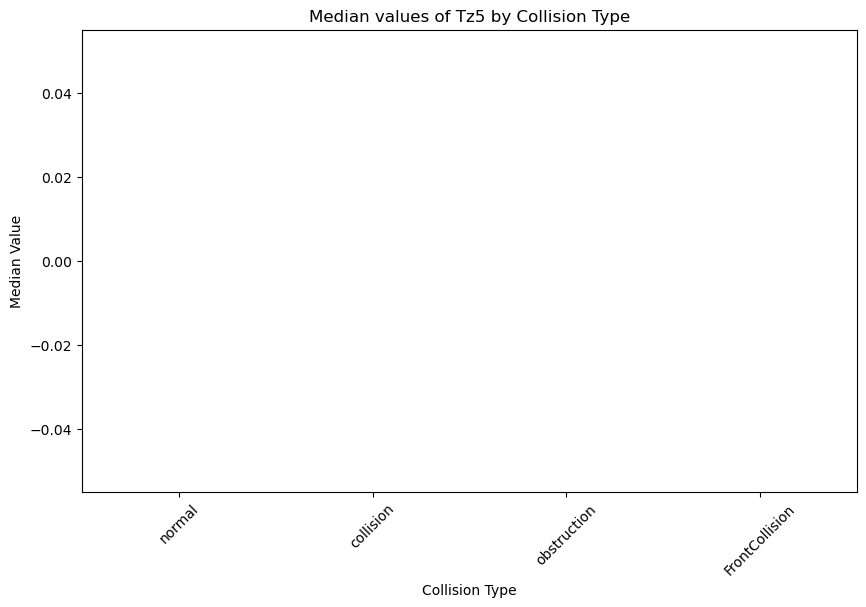

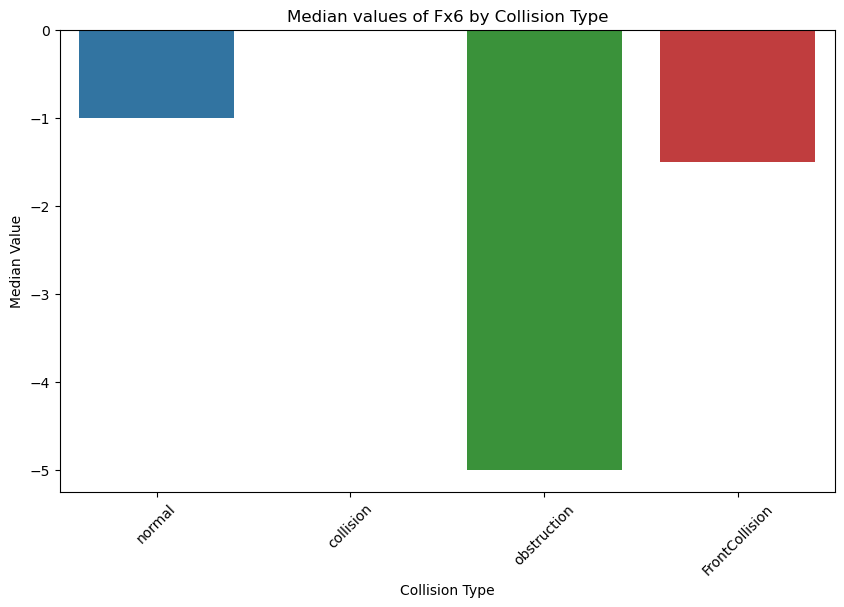

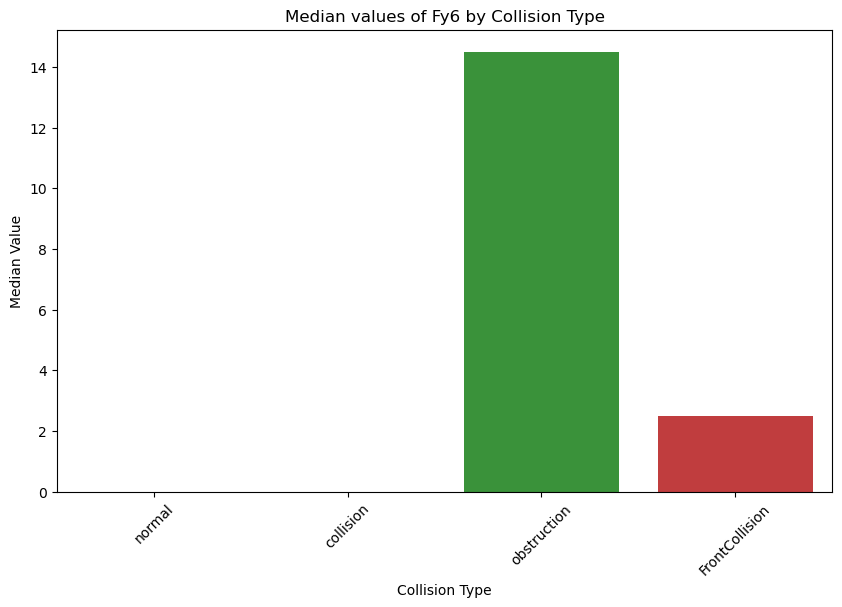

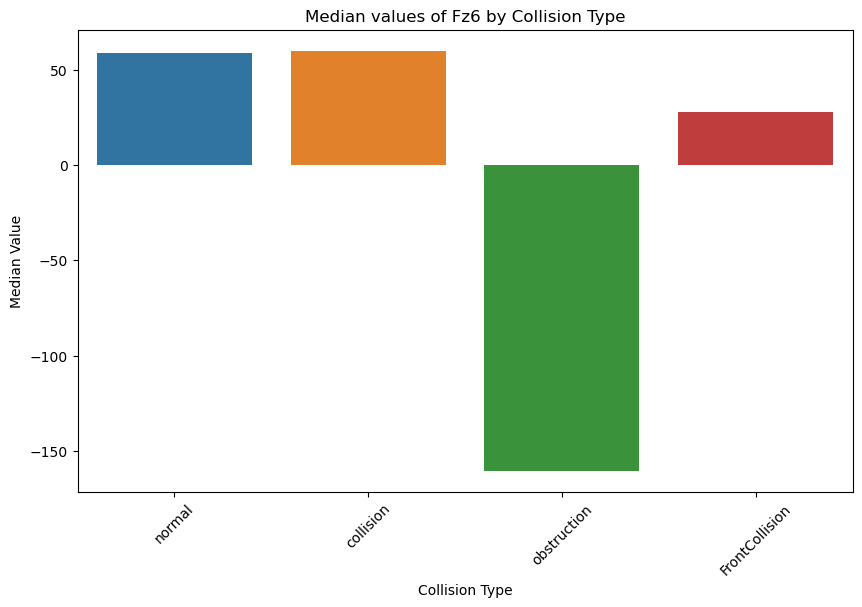

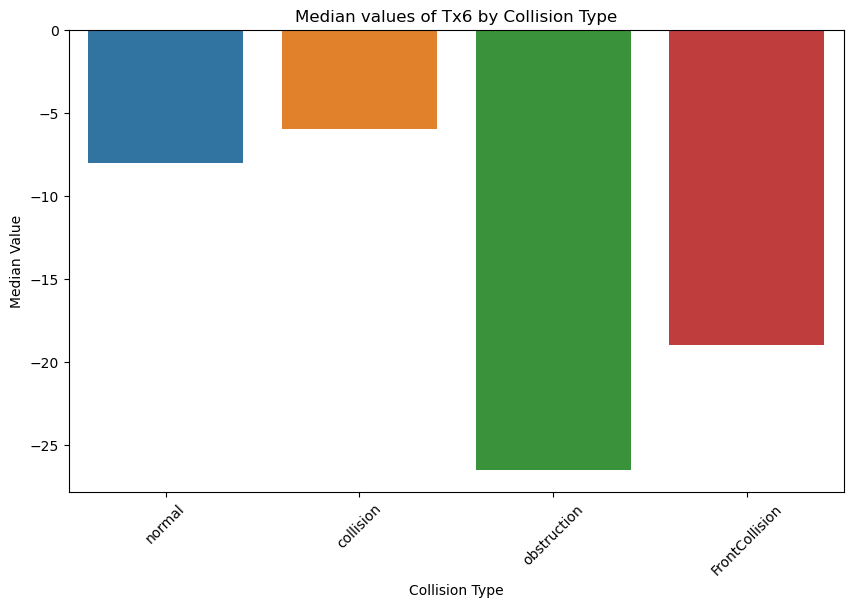

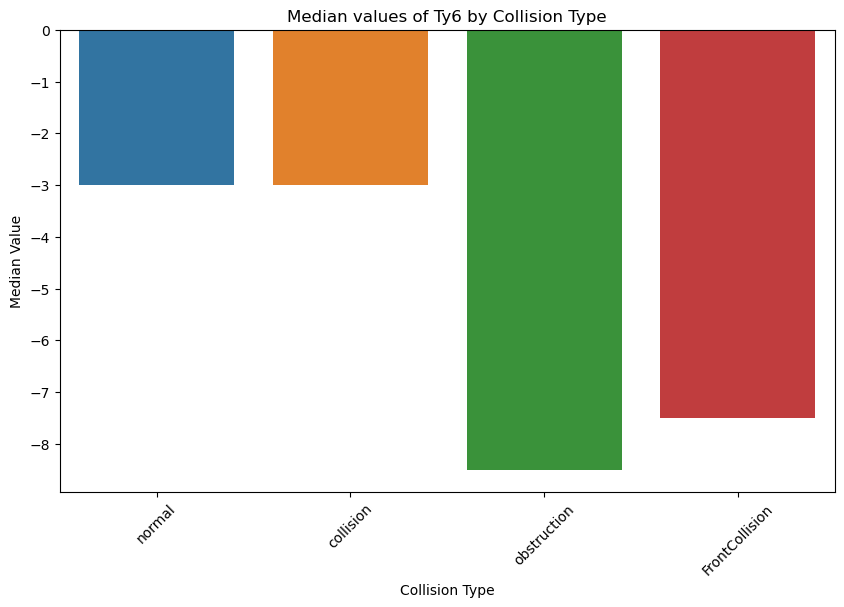

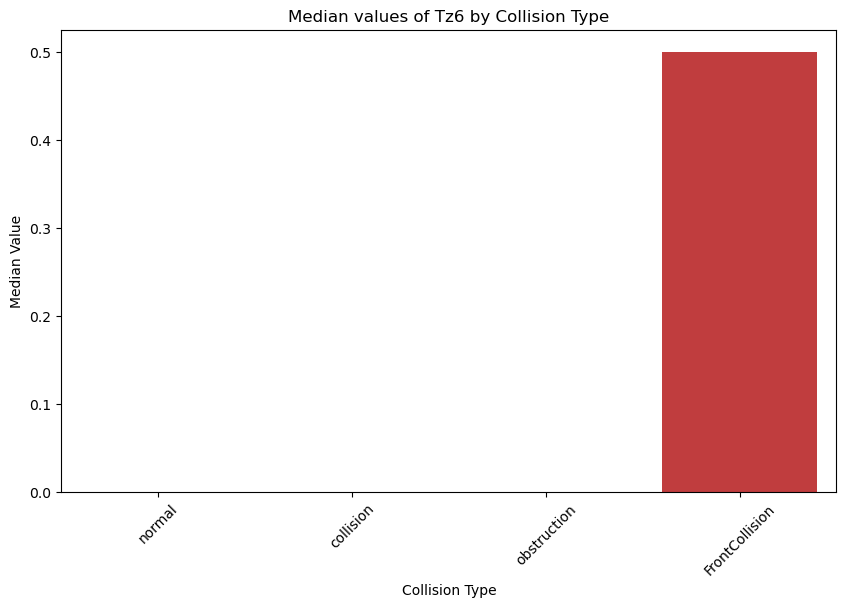

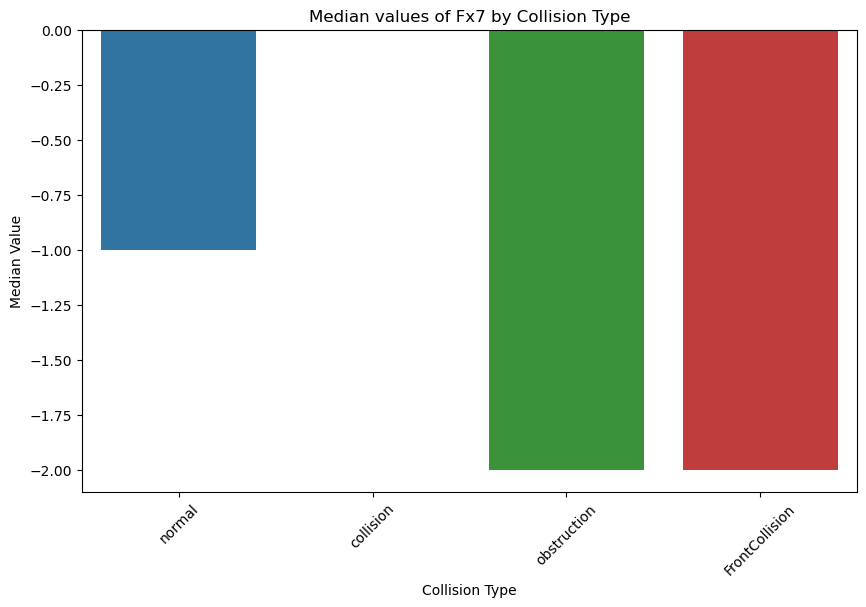

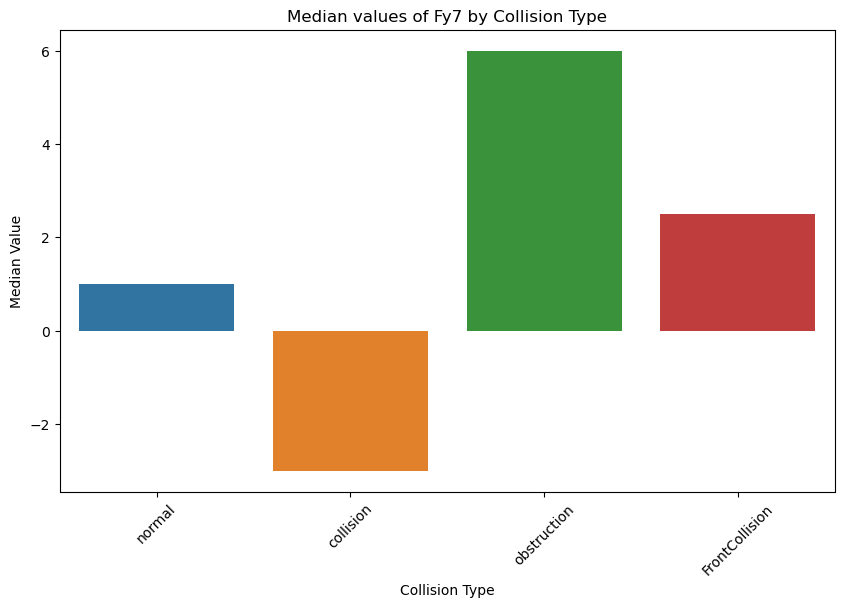

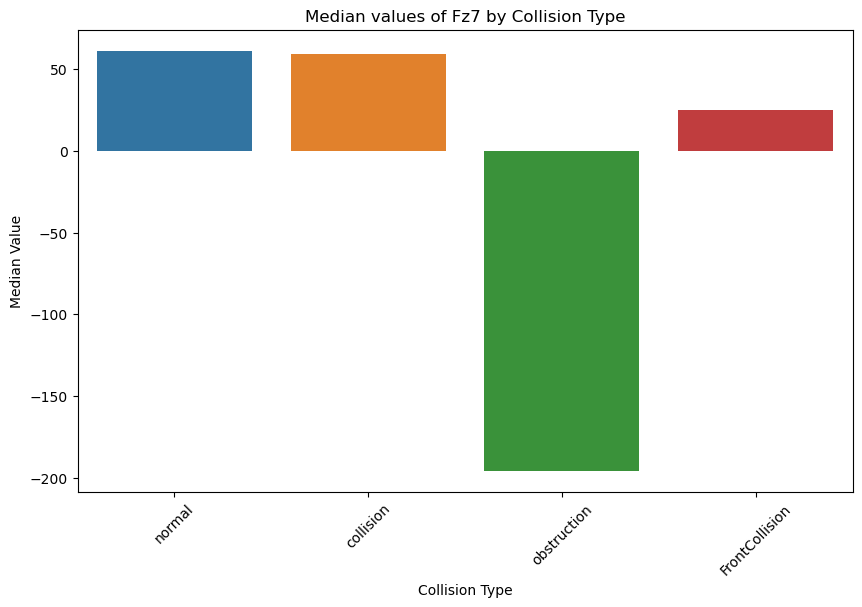

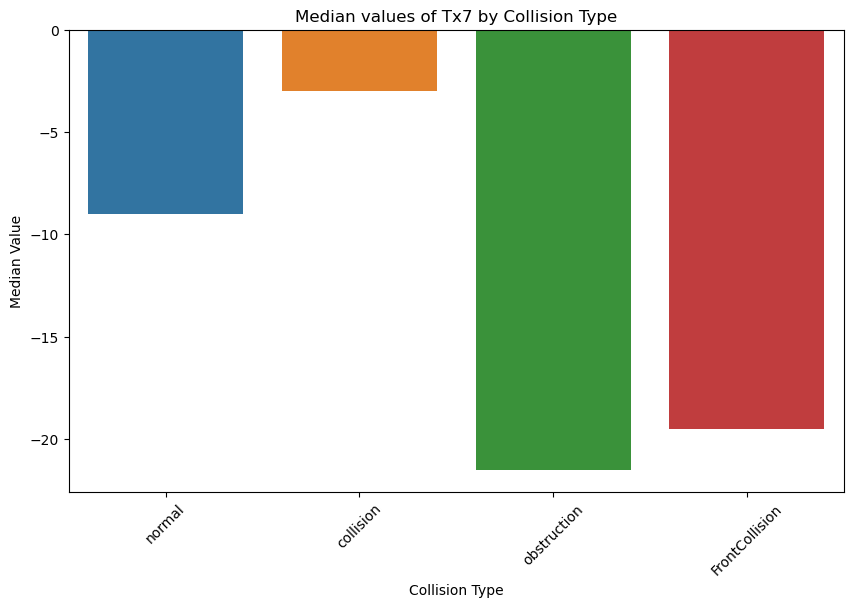

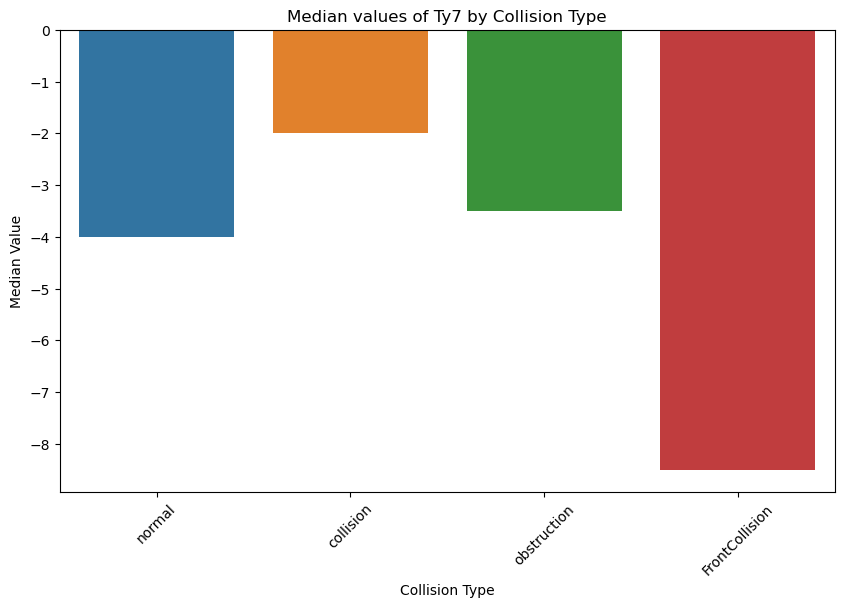

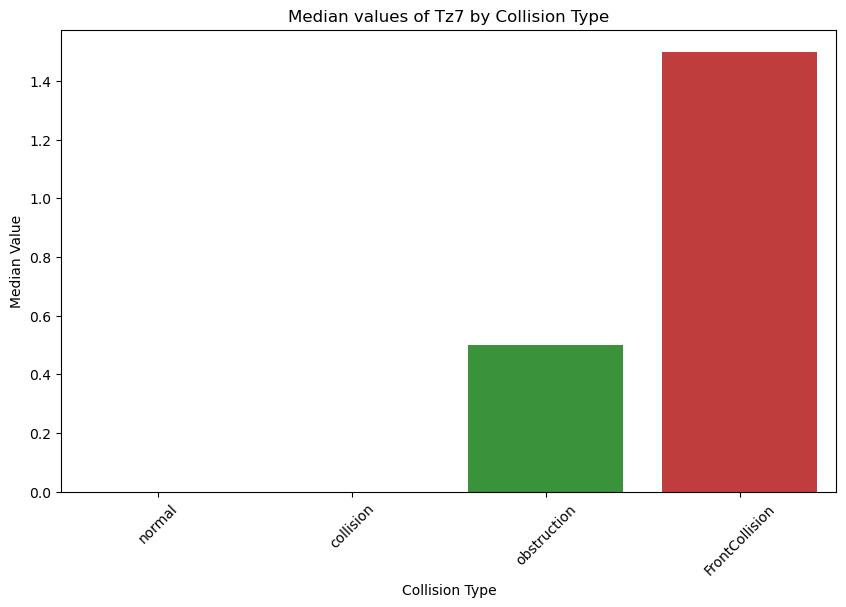

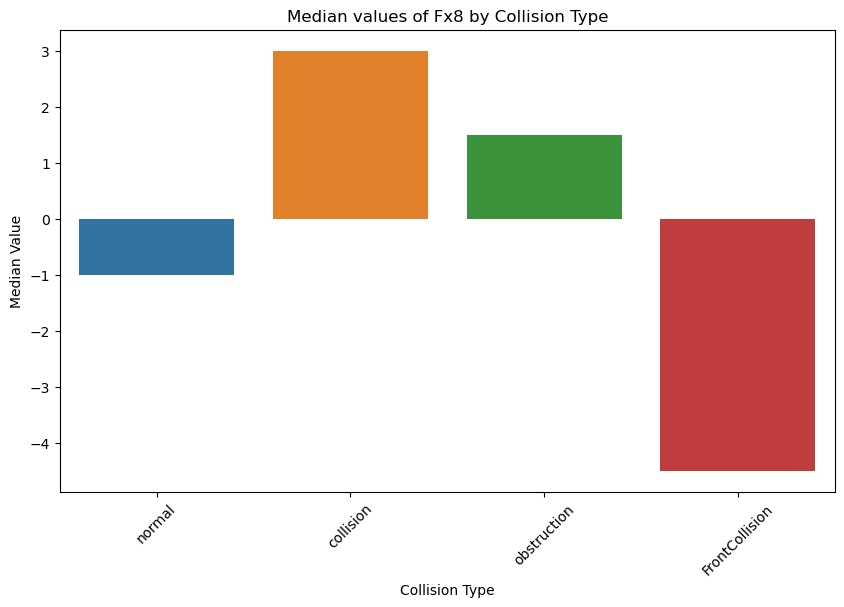

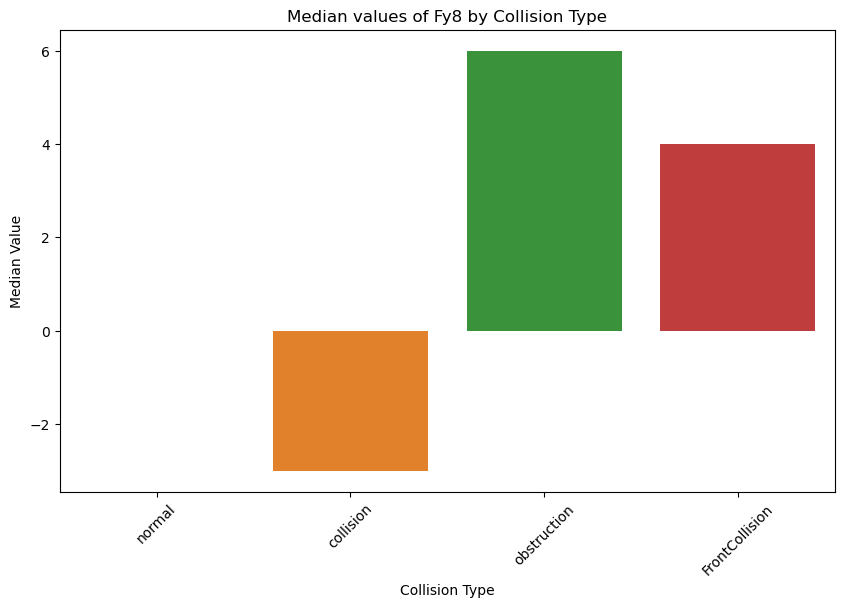

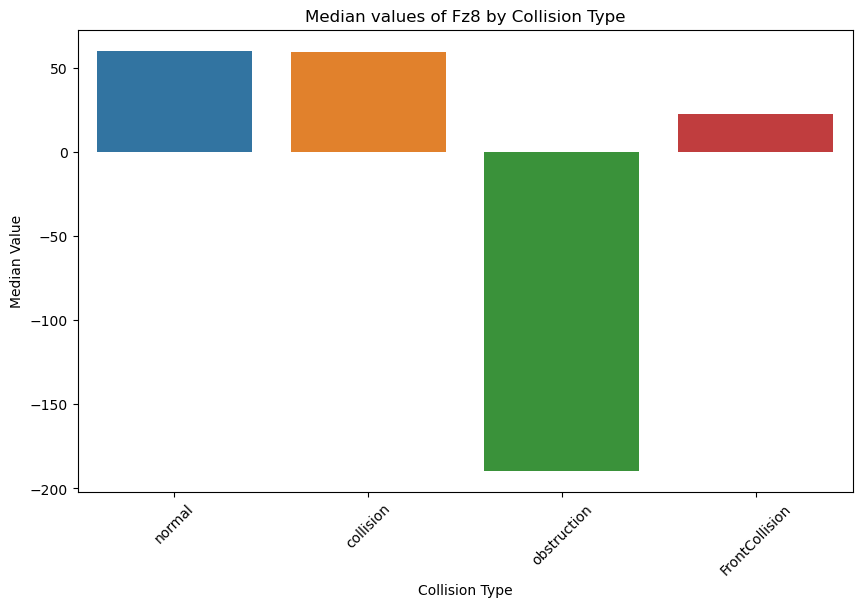

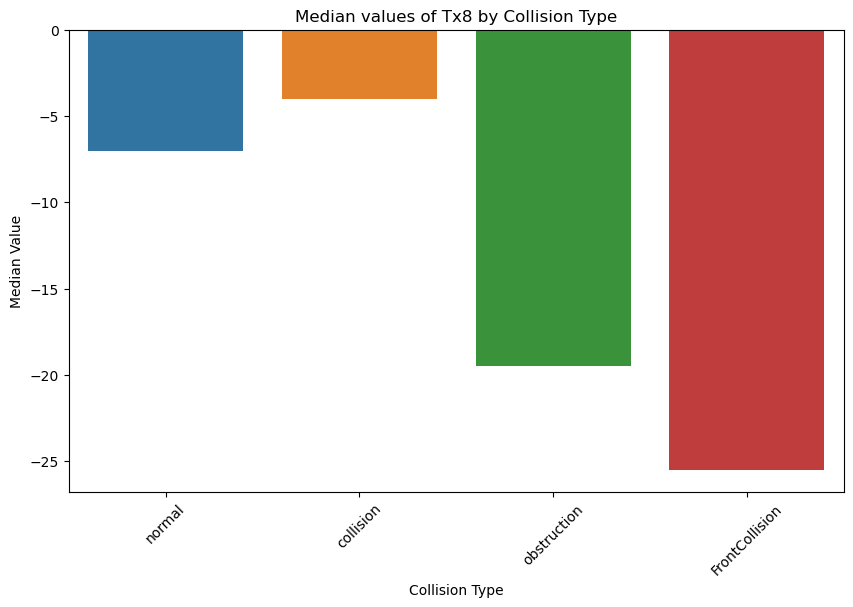

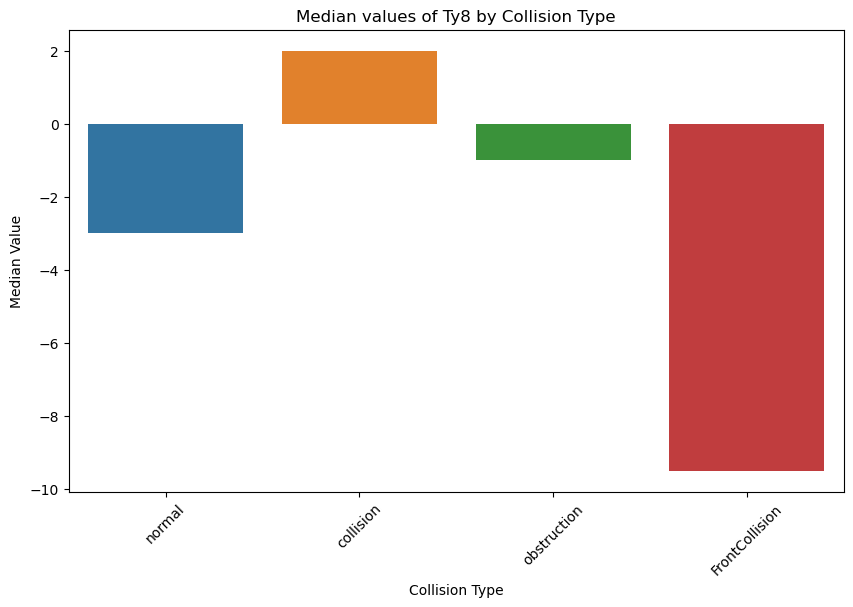

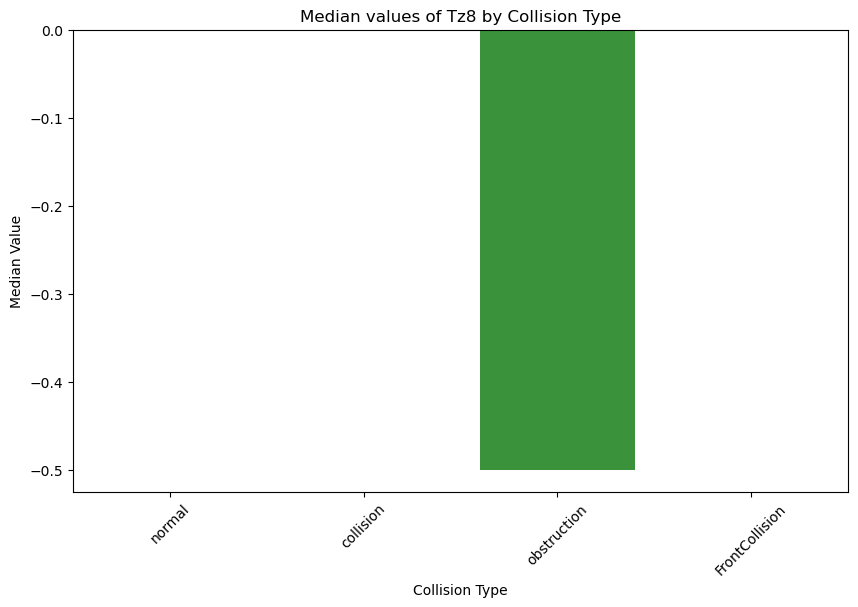

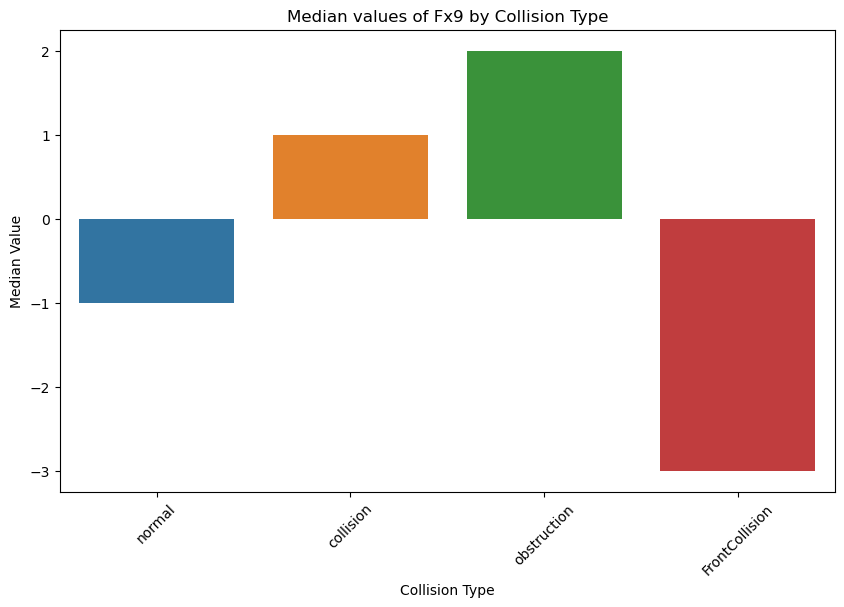

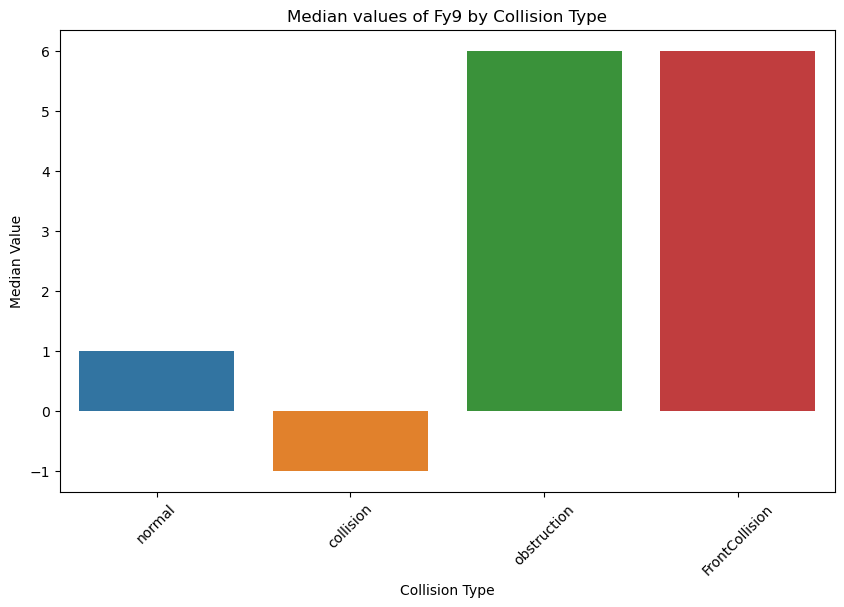

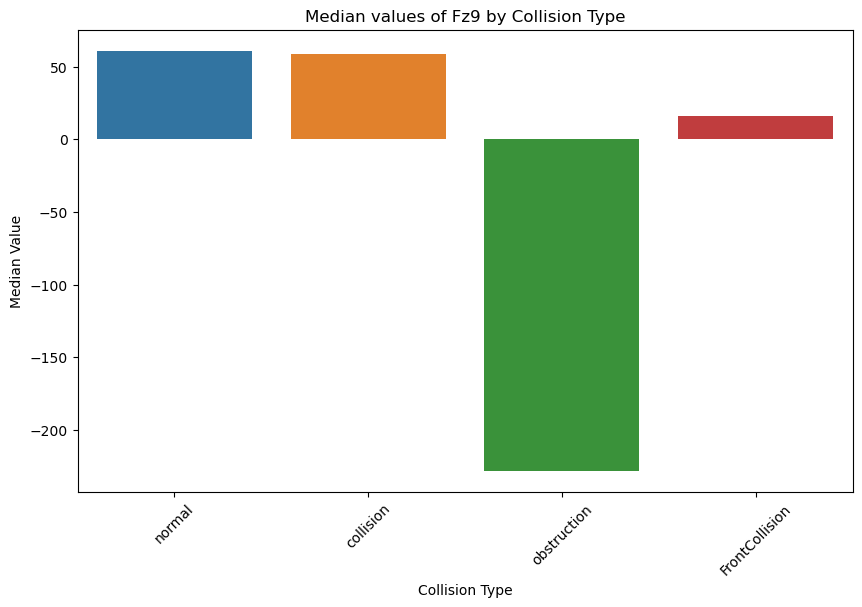

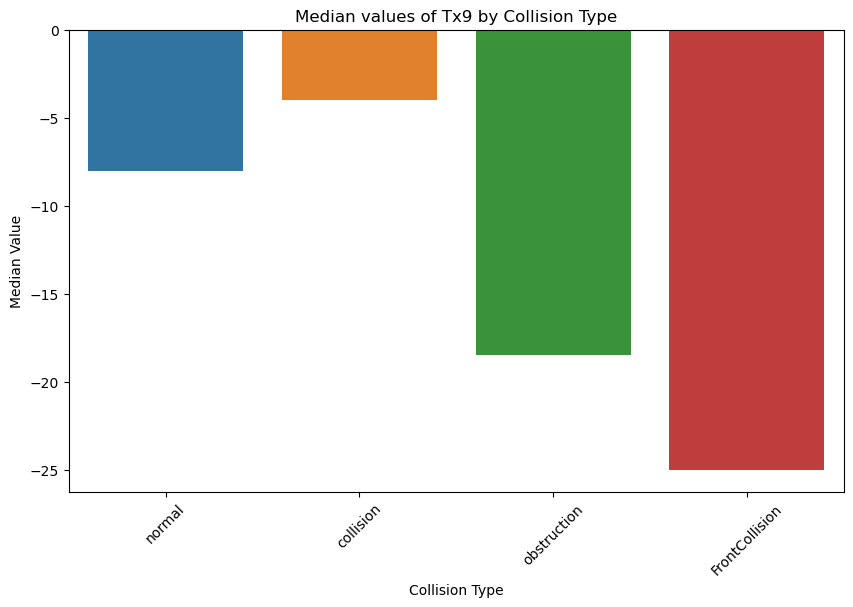

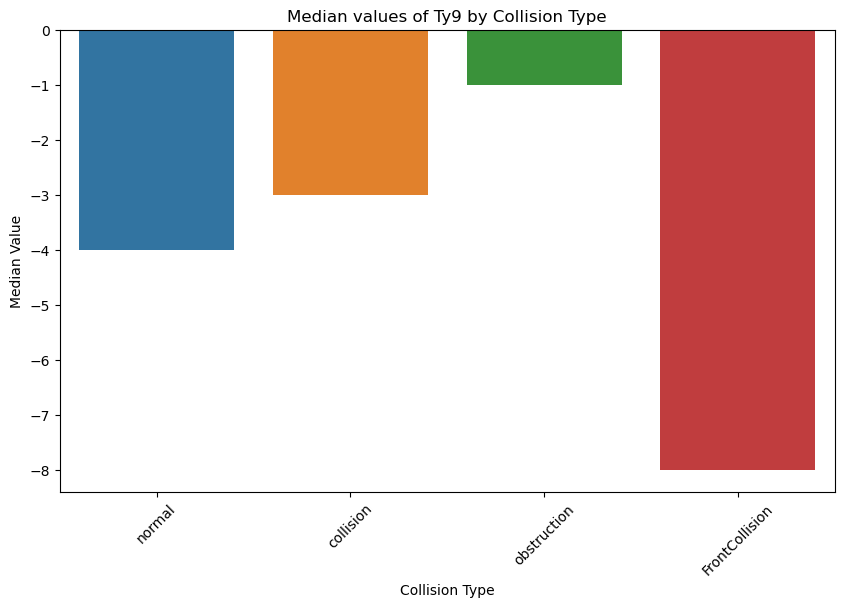

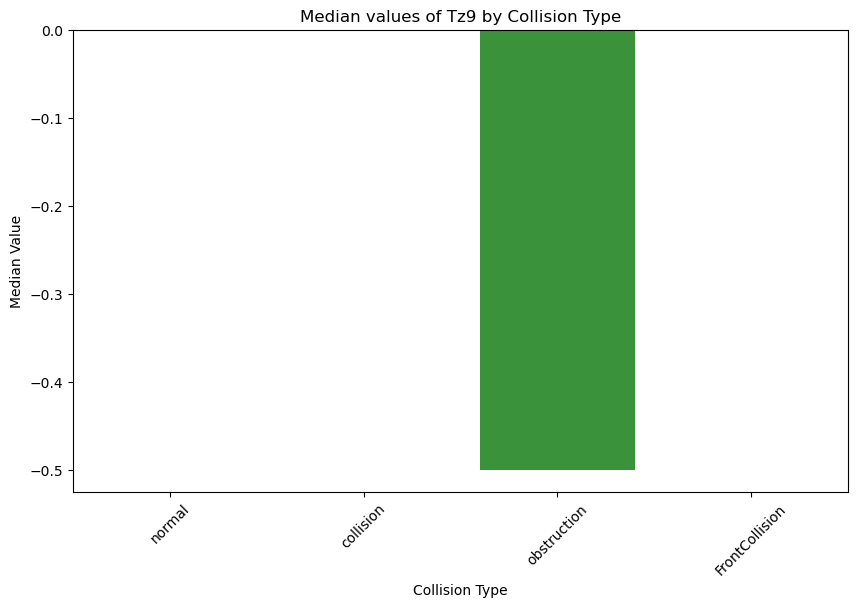

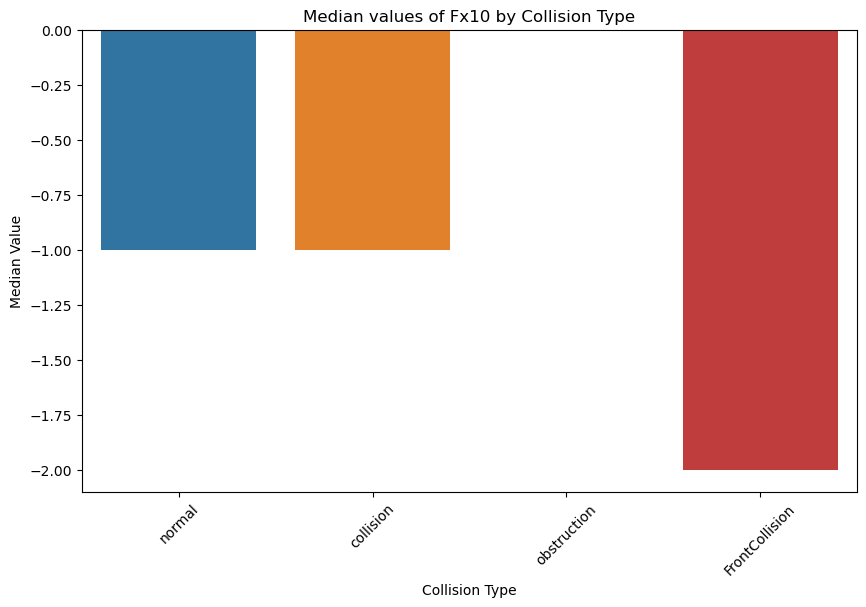

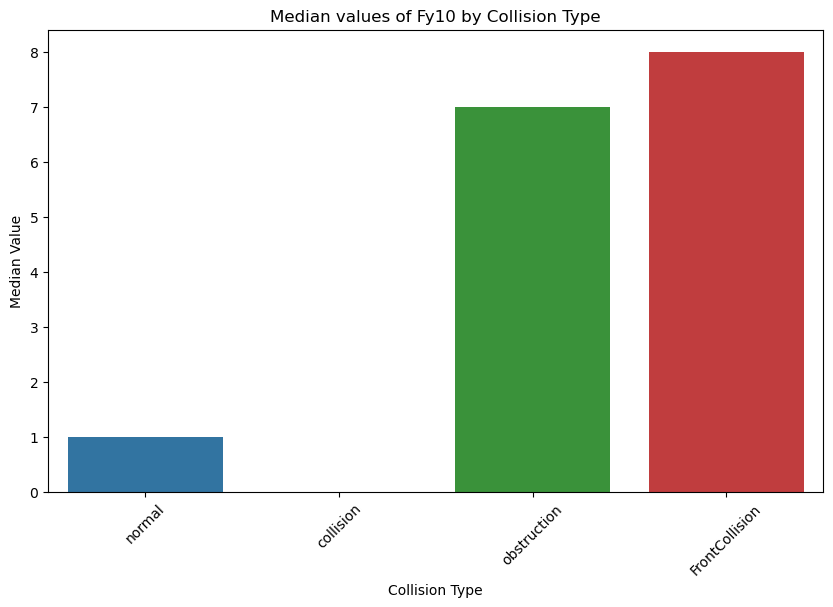

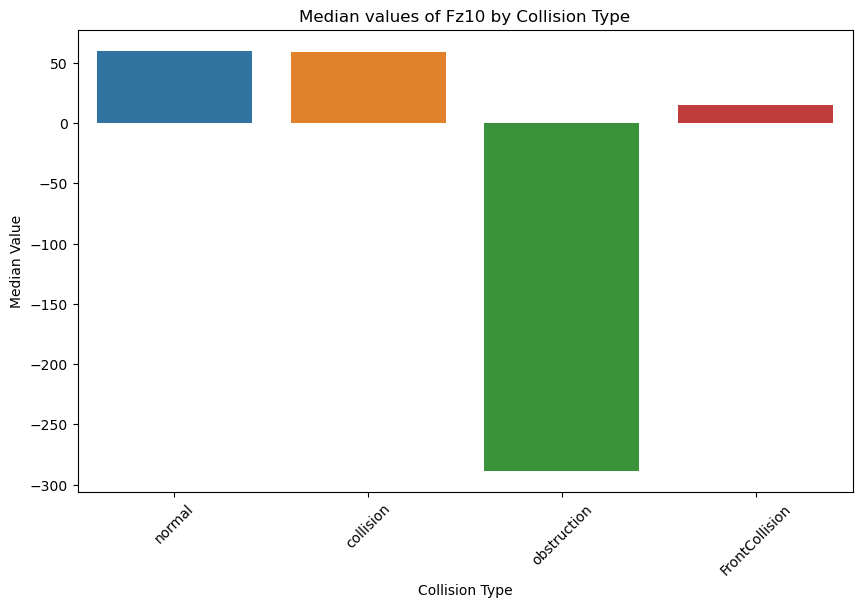

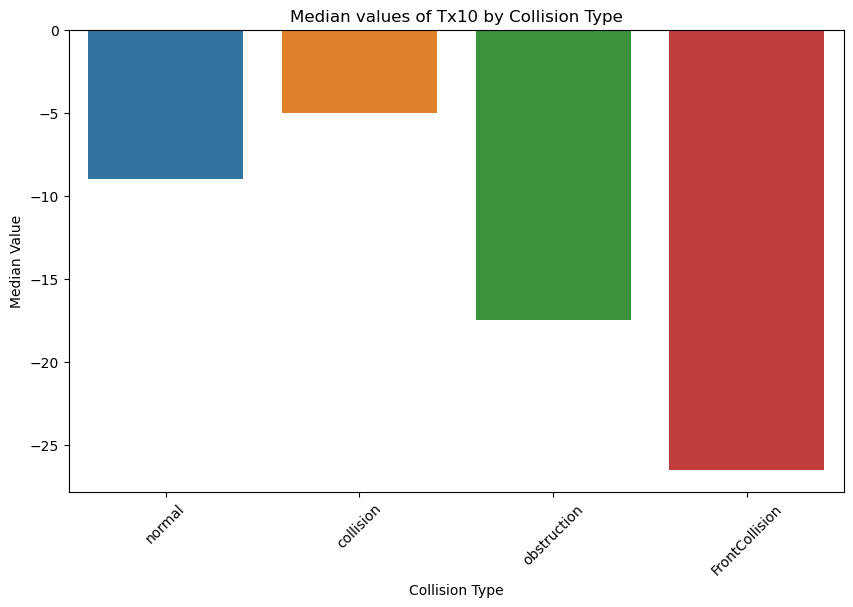

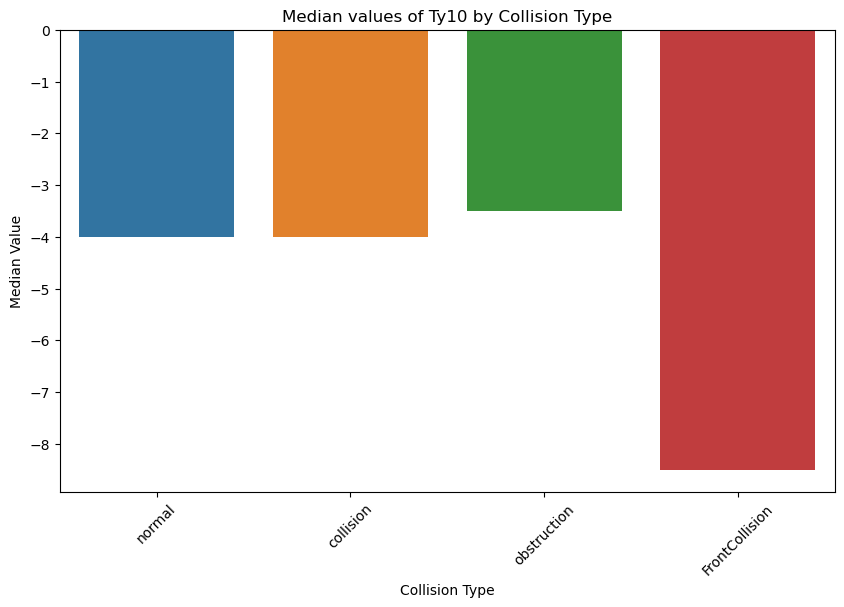

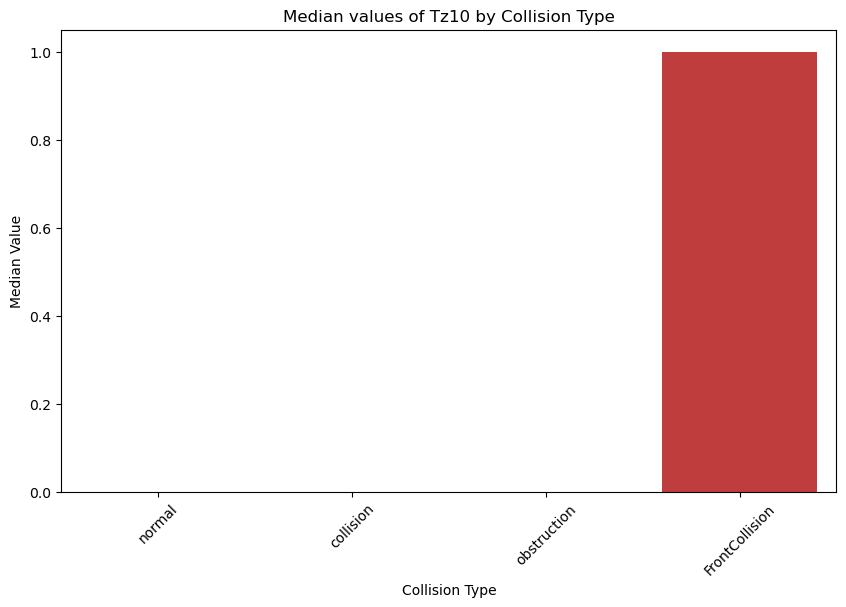

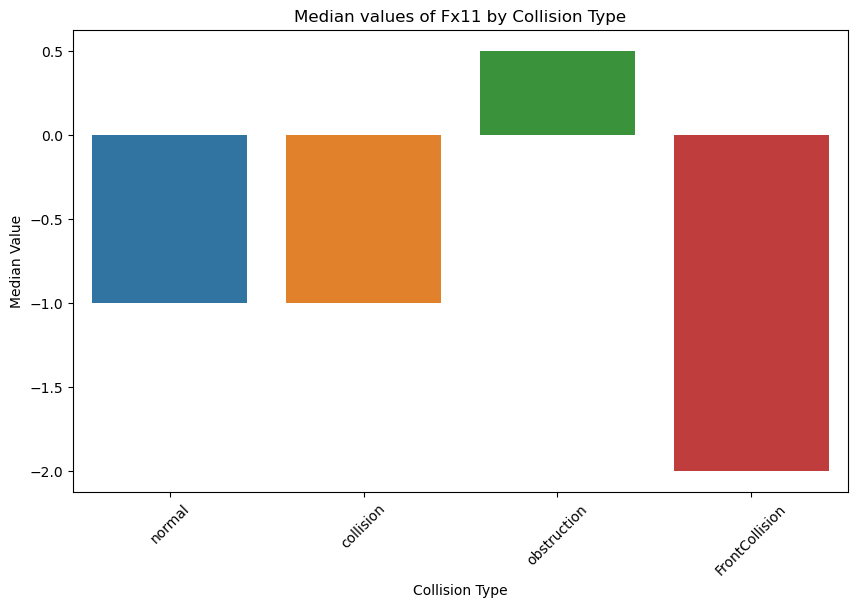

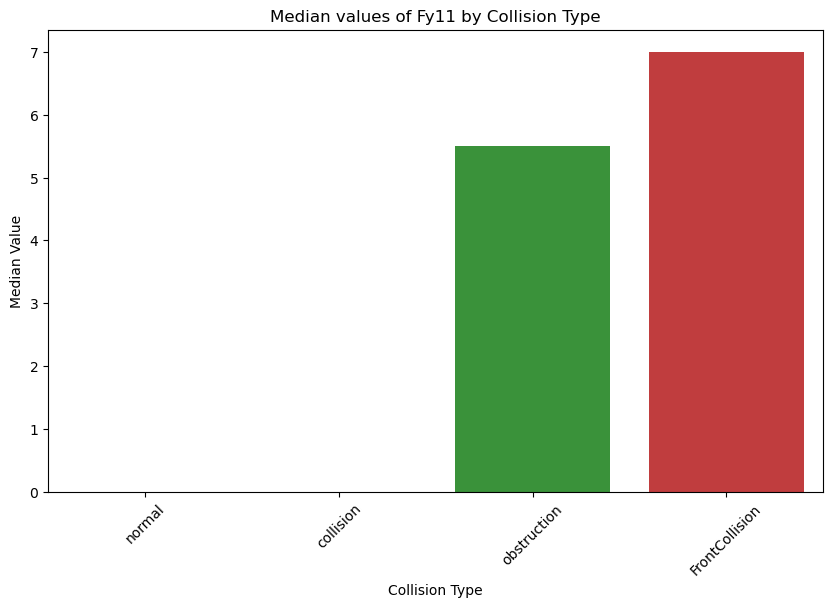

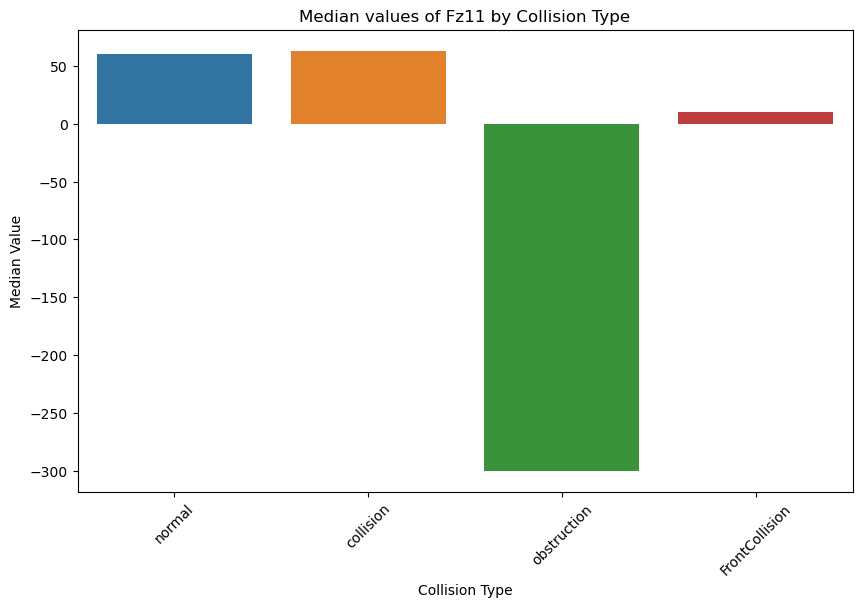

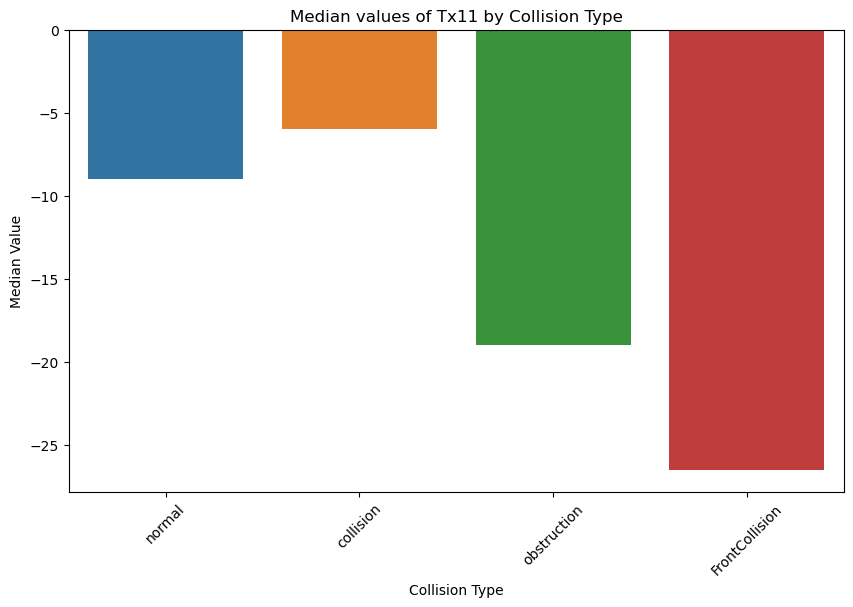

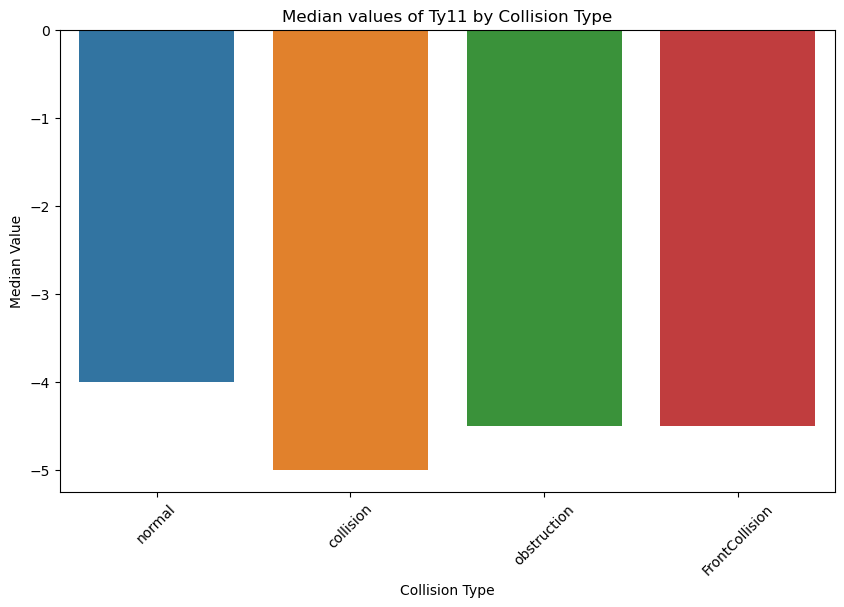

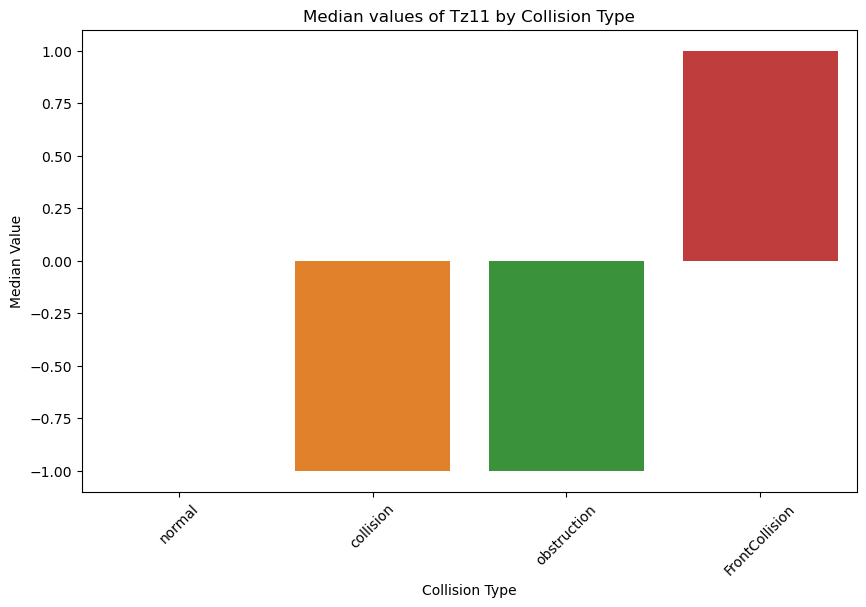

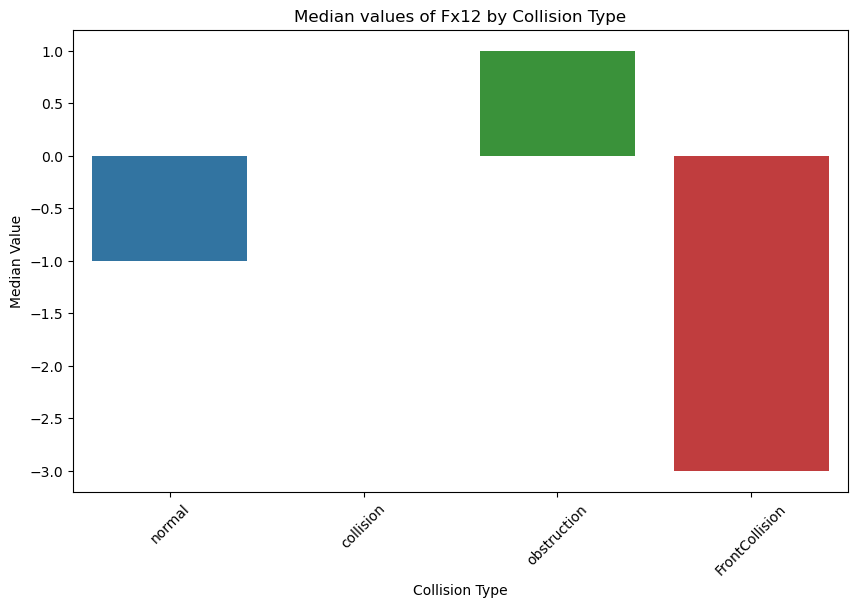

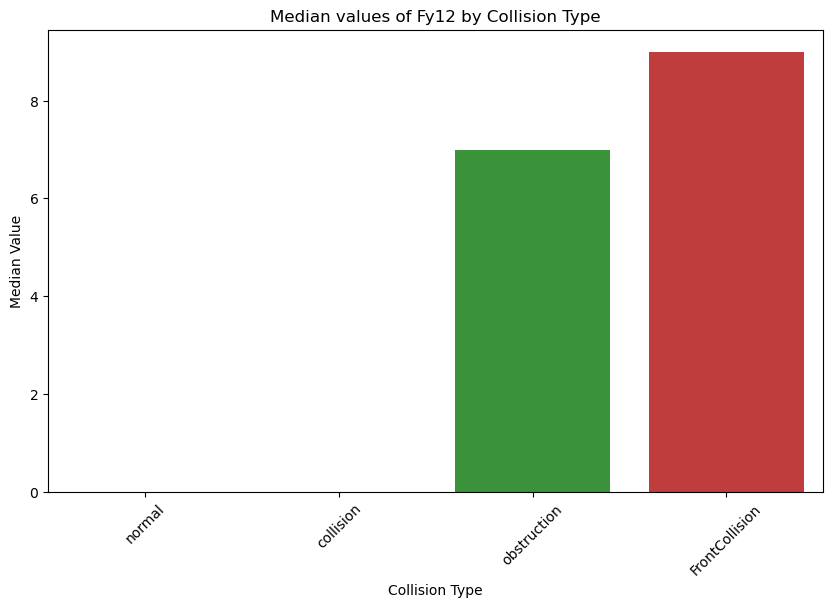

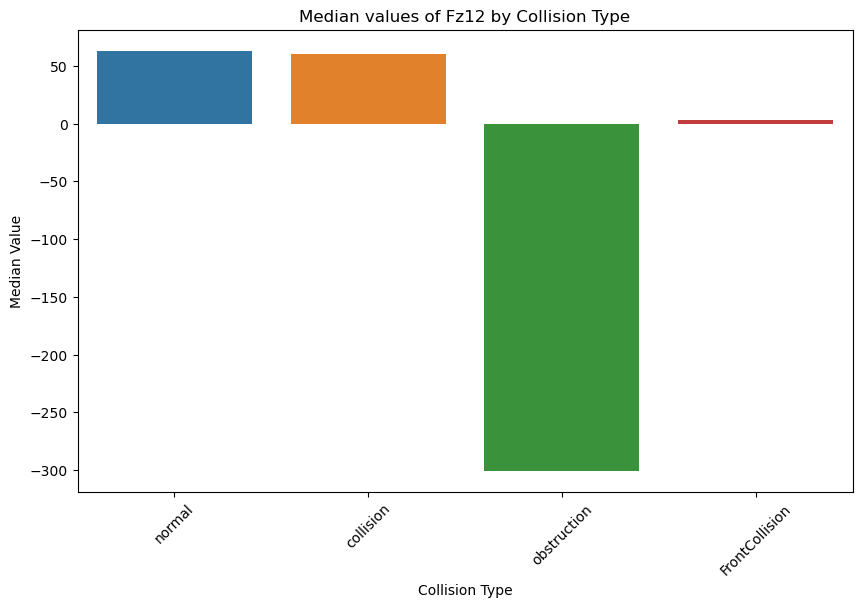

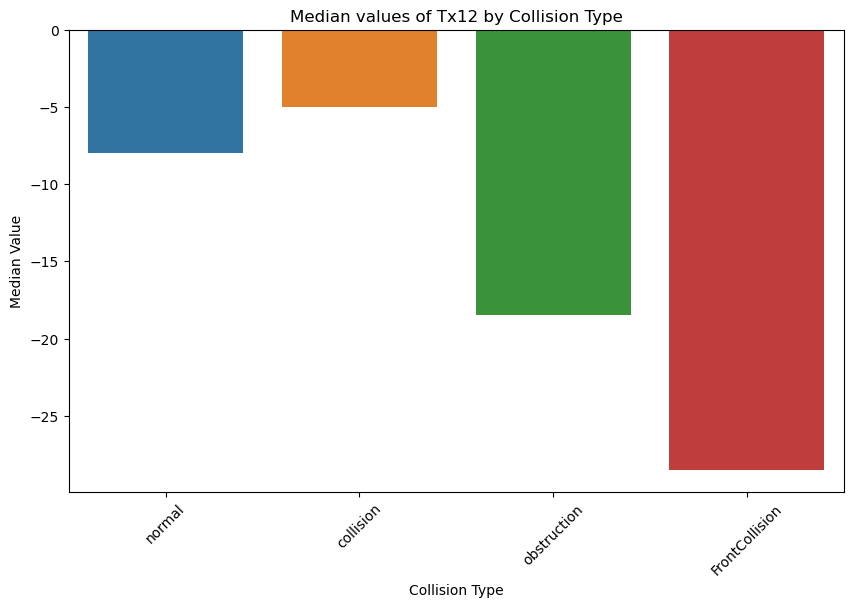

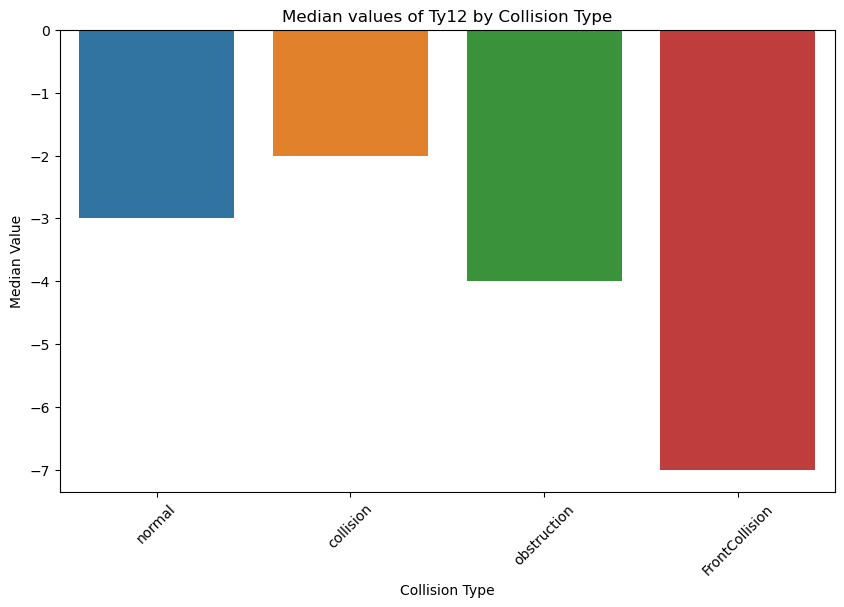

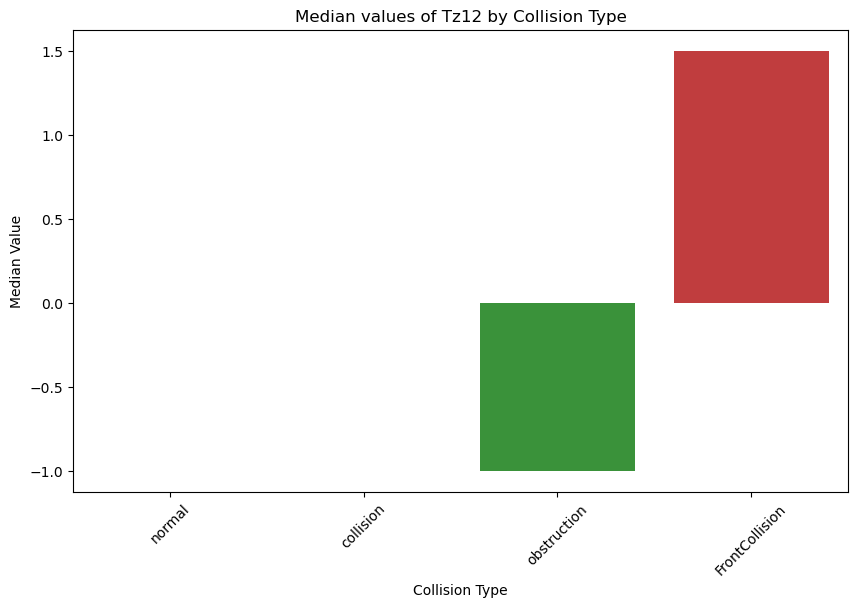

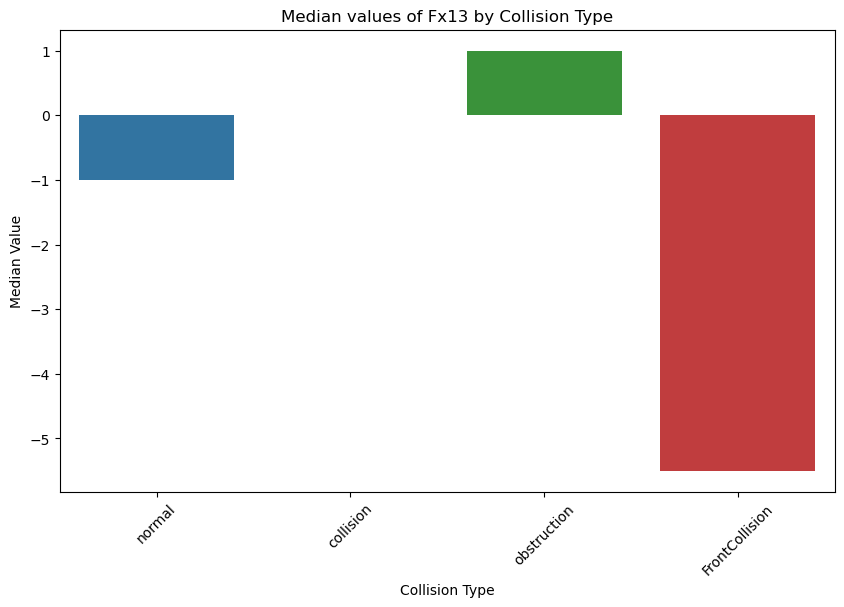

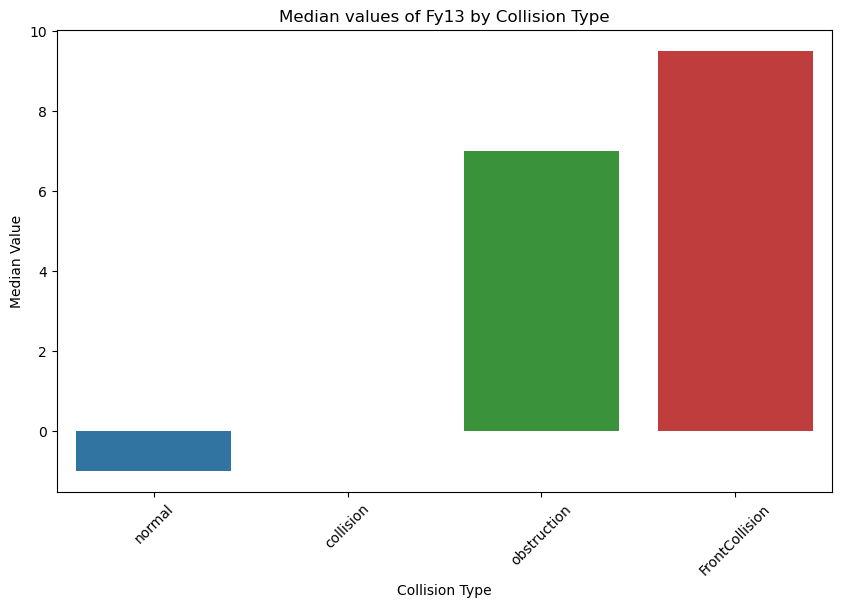

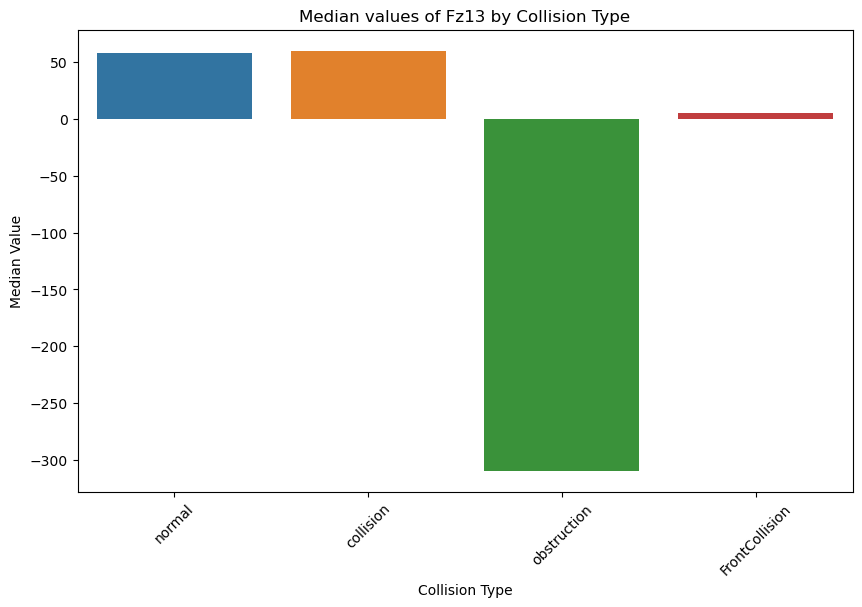

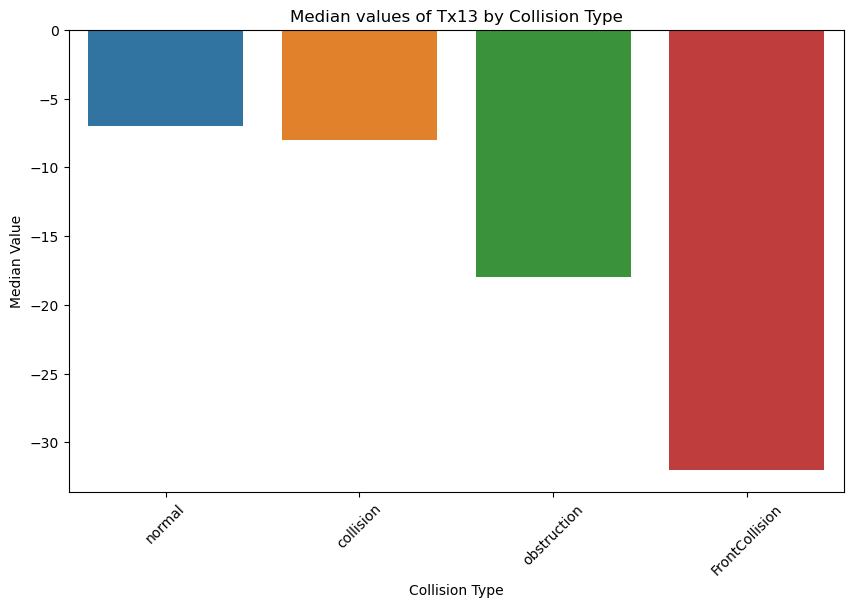

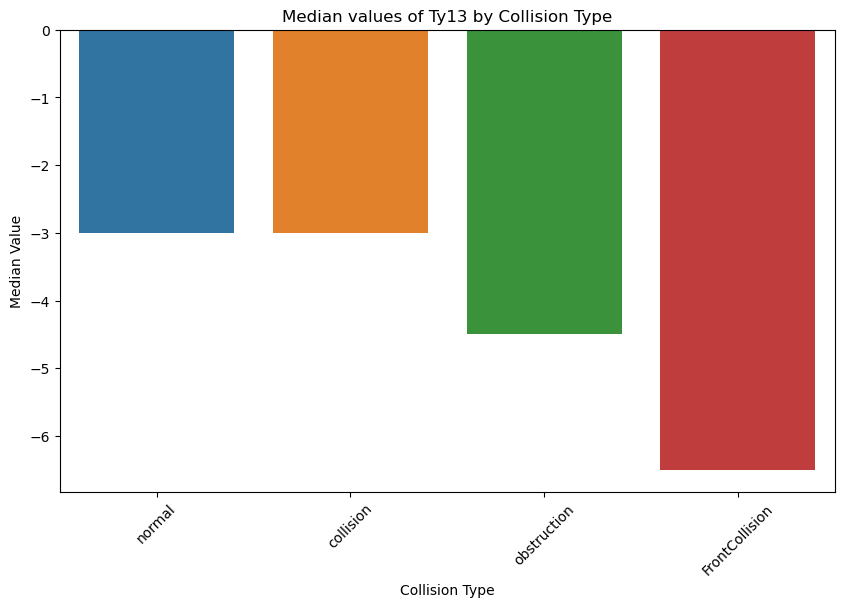

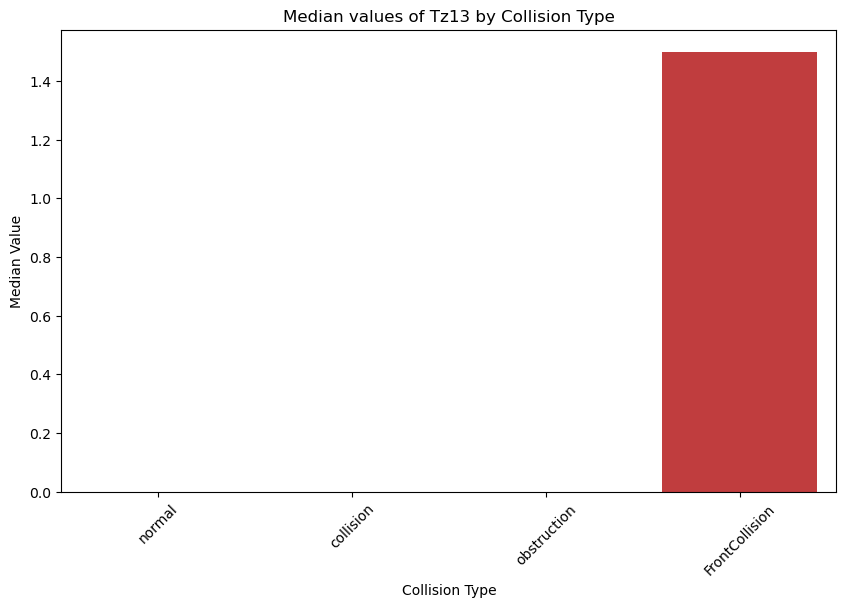

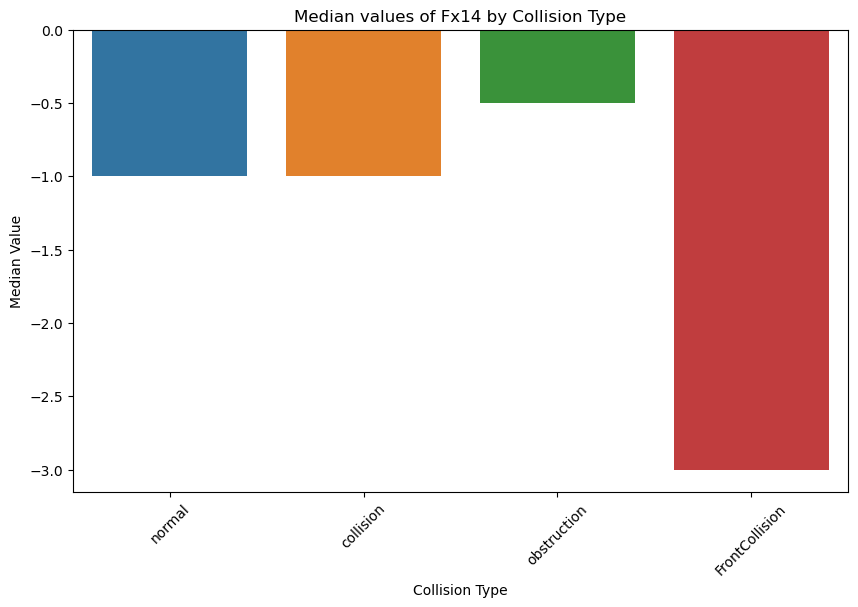

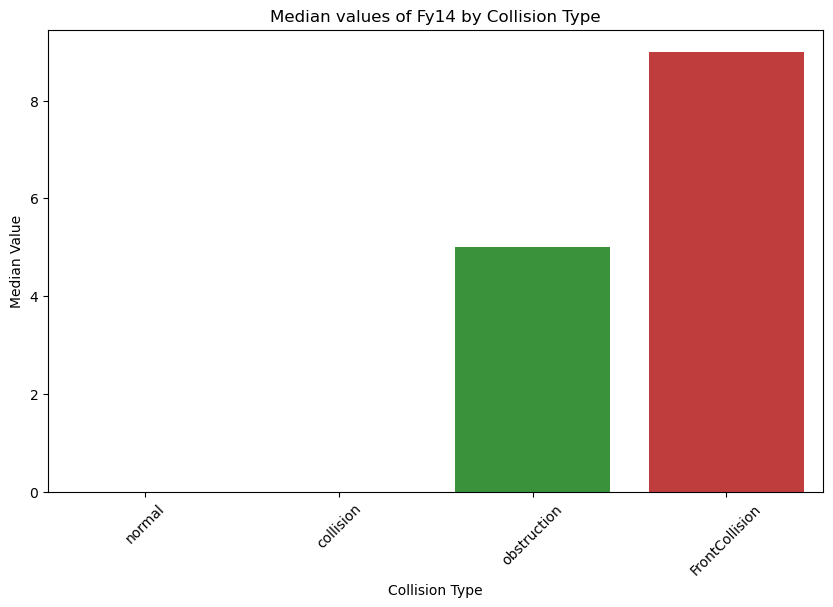

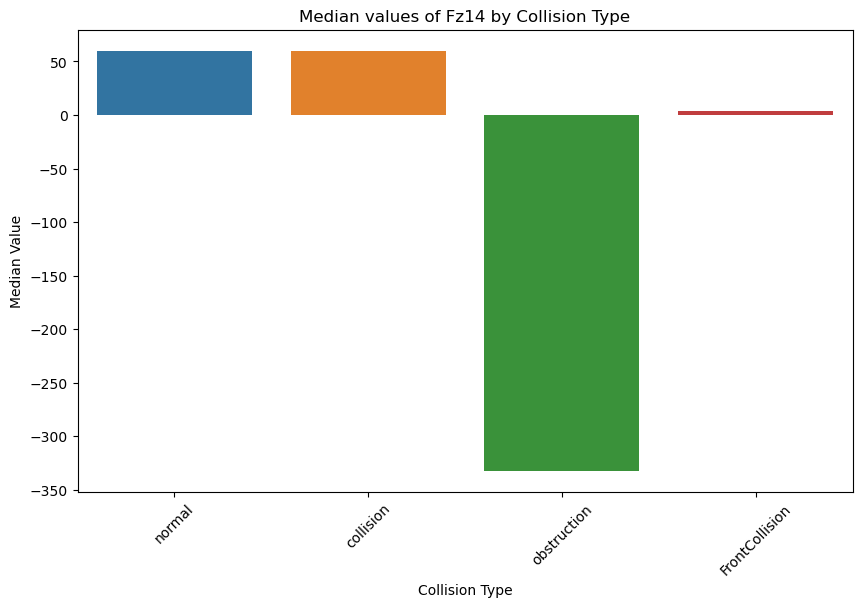

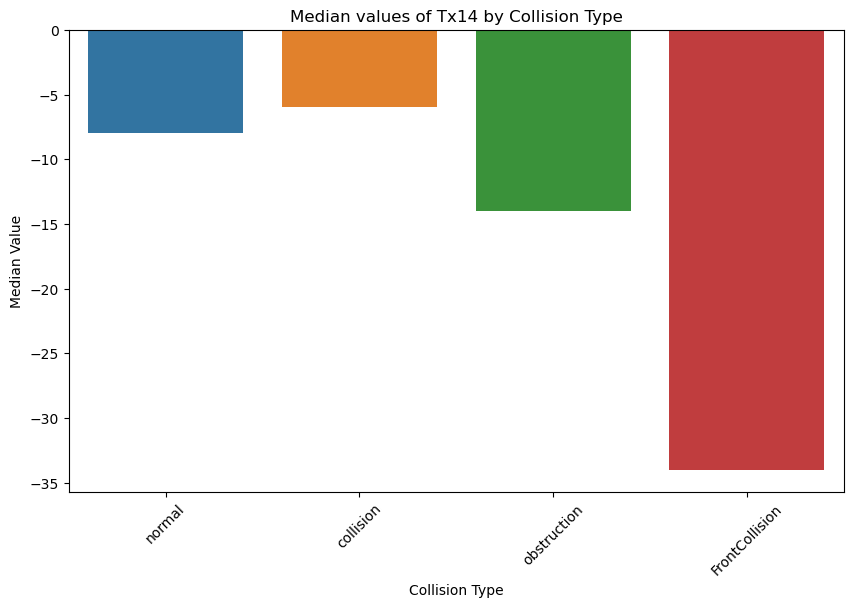

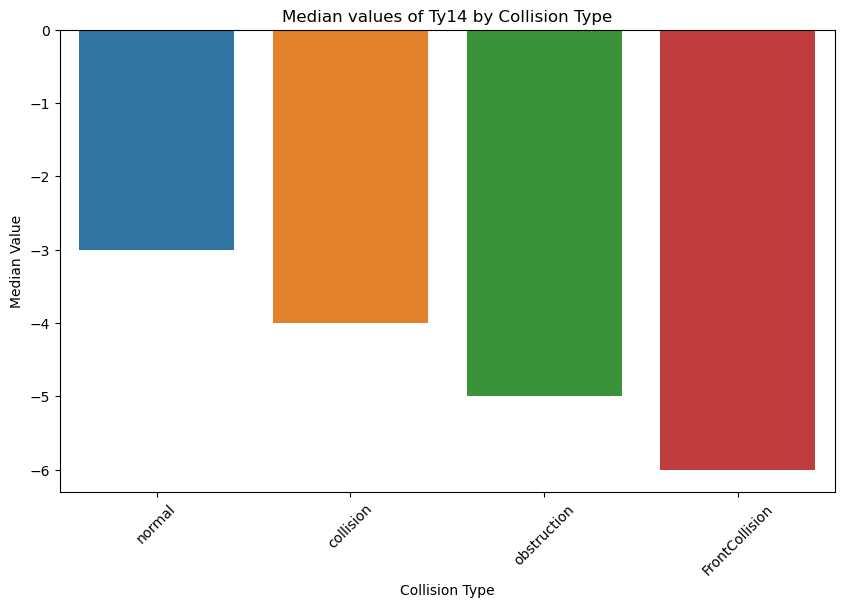

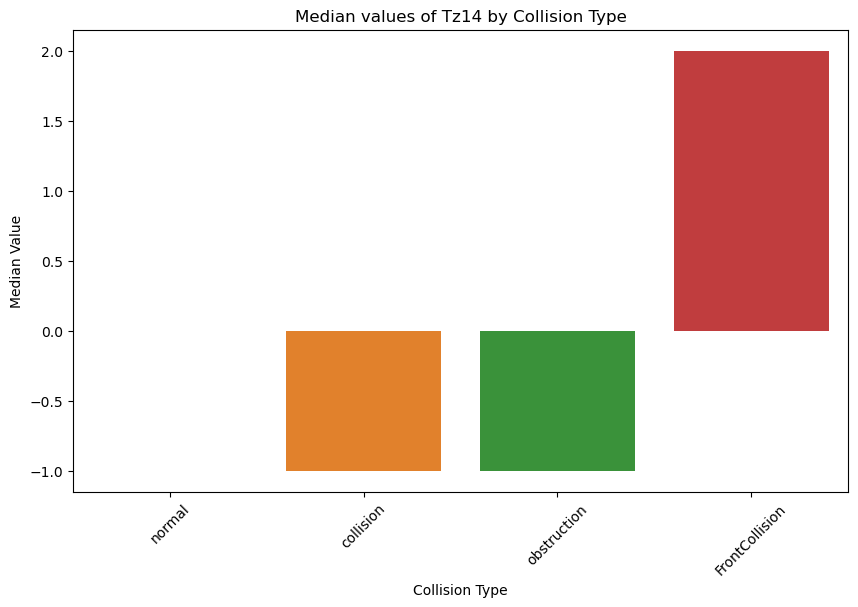

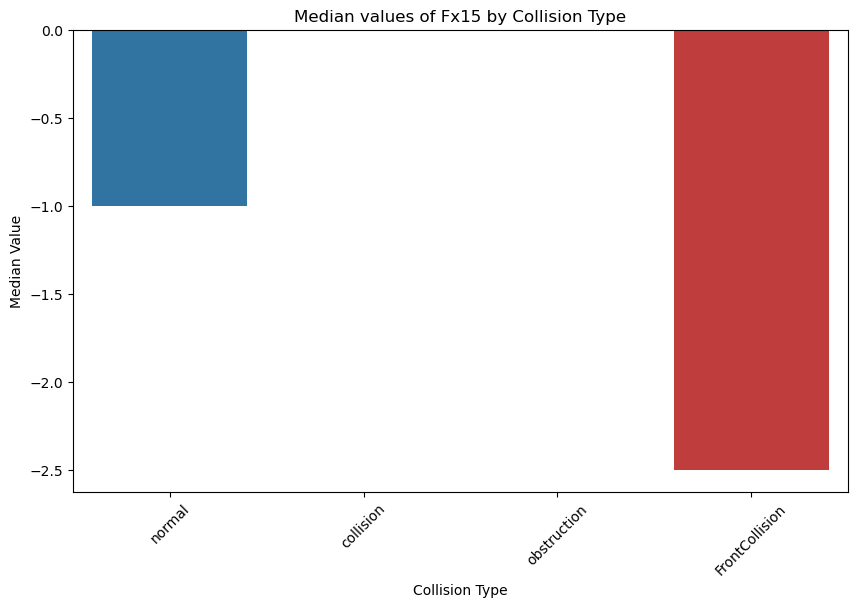

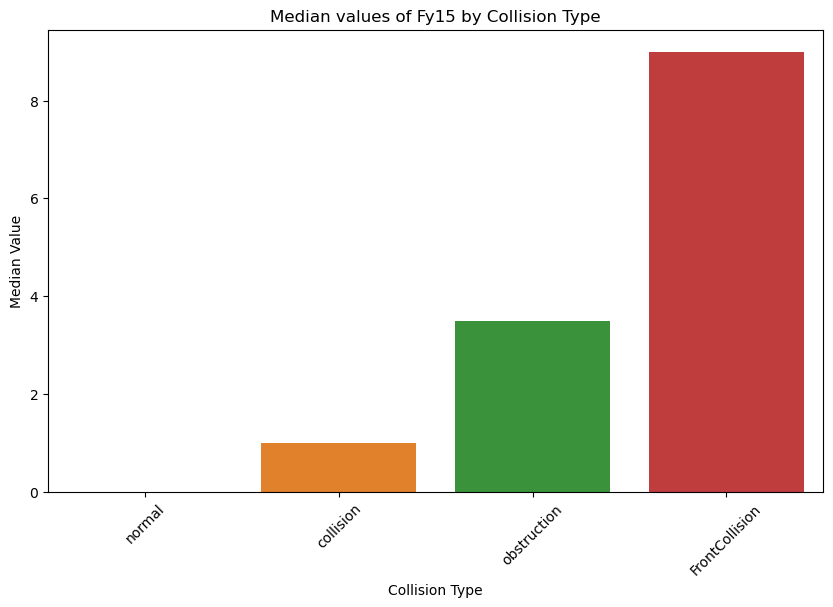

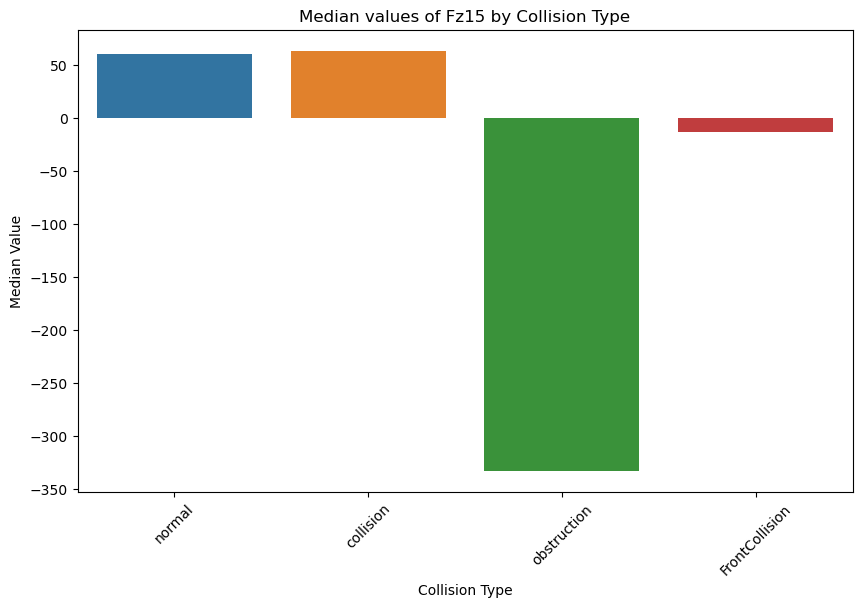

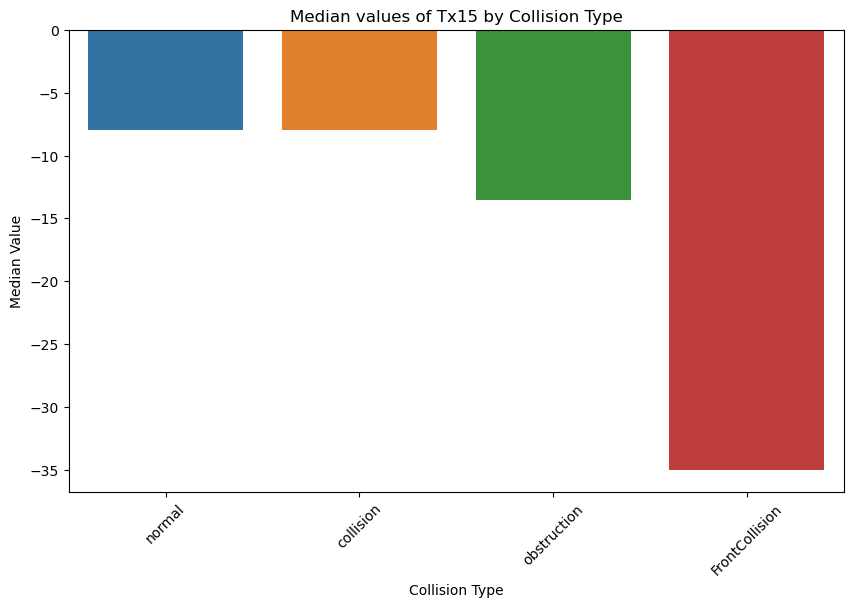

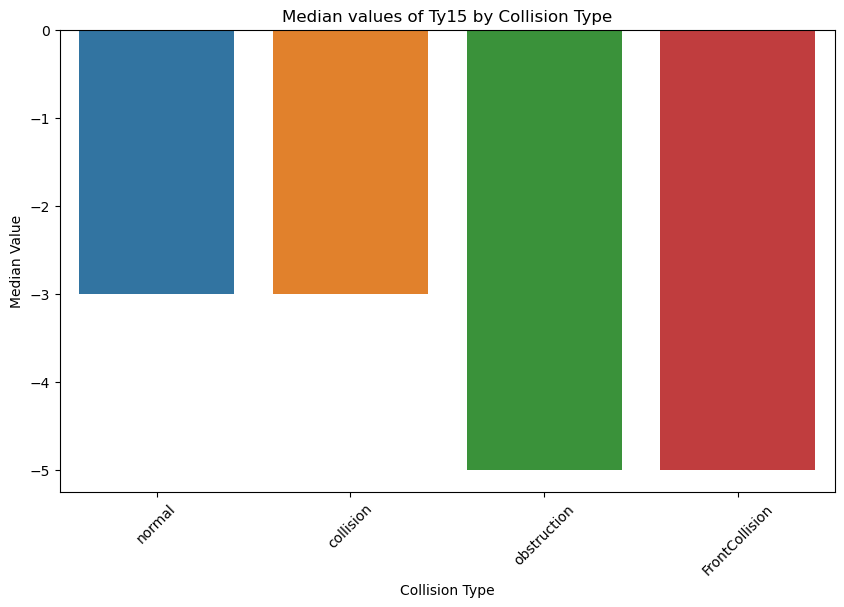

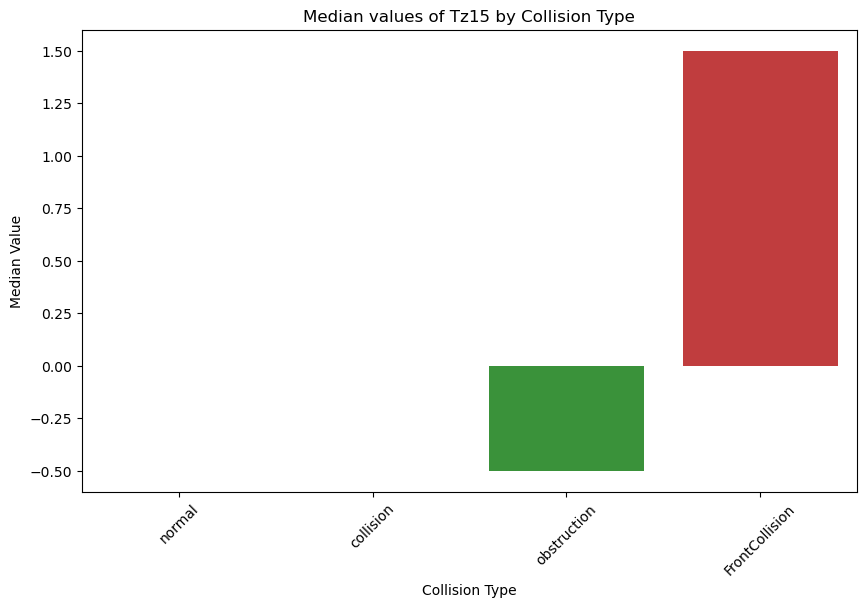

In [70]:
plt.figure(figsize=(10, 10))

# Loop over each column (except for 'Collision Type')
for column in Mediandf.columns:
    plt.figure(figsize=(10, 6))
    sns.barplot(x=Mediandf.index, y=column, data=Mediandf)
    plt.title(f"Median values of {column} by Collision Type")
    plt.ylabel('Median Value')
    plt.xlabel('Collision Type')
    plt.xticks(rotation=45)
    plt.show()